<a href="https://colab.research.google.com/github/Jorgellamocca/S2S-PER/blob/main/Lima_diario.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# ============================================================
# REPARAR SCIPY EN GOOGLE COLAB
# ============================================================

import sys
import subprocess

subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "--no-cache-dir",
        "--force-reinstall",
        "--no-deps",
        "scipy==1.16.3"
    ],
    check=True
)

print("SciPy reinstalado correctamente.")
print("REINICIA AHORA LA SESIÓN DE COLAB.")

SciPy reinstalado correctamente.
REINICIA AHORA LA SESIÓN DE COLAB.


Mounted at /content/drive

PREPARACIÓN DE CARTOGRAFÍA
Distritos: 52
Tramos de ríos: 34
Malla de representación: 91 x 126

PROCESAMIENTO DEM ASTER


Cobertura DEM: 73.9%

CONSULTA ECMWF IFS
Inicialización: 2026-11-06 00:00:00+00:00
Descargando: tp


<multiple>:   0%|          | 0.00/82.1M [00:00<?, ?B/s]

By downloading data from the ECMWF open data dataset, you agree to the terms: Attribution 4.0 International (CC BY 4.0). Please attribute ECMWF when downloading this data.
OK: (41, 40, 40)
Descargando: 2t


<multiple>:   0%|          | 0.00/54.1M [00:00<?, ?B/s]

OK: (41, 40, 40)
Descargando: 2d


... (5 outputs left out)

OK: (41, 40, 40)
Descargando: lcc


<multiple>:   0%|          | 0.00/90.8M [00:00<?, ?B/s]

OK: (41, 40, 40)
Interpolando: tp
Interpolando: 2t
Interpolando: 2d
Interpolando: 10u
Interpolando: 10v
Interpolando: lcc

6 DE NOVIEMBRE


/tmp/ipykernel_1859/3079149436.py:1359: RuntimeWarning: Mean of empty slice
  np.nanmean(


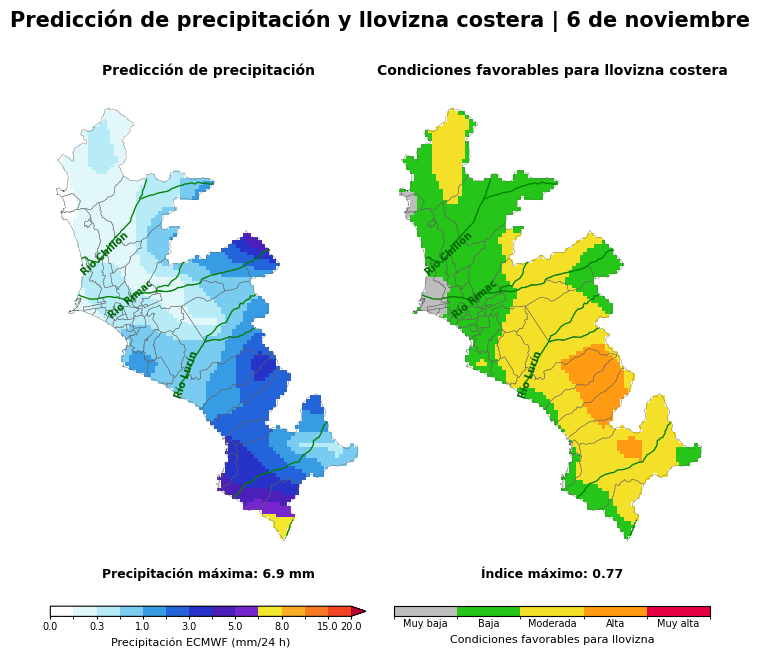

No se identificaron distritos con índice medio >= 0.60.

7 DE NOVIEMBRE


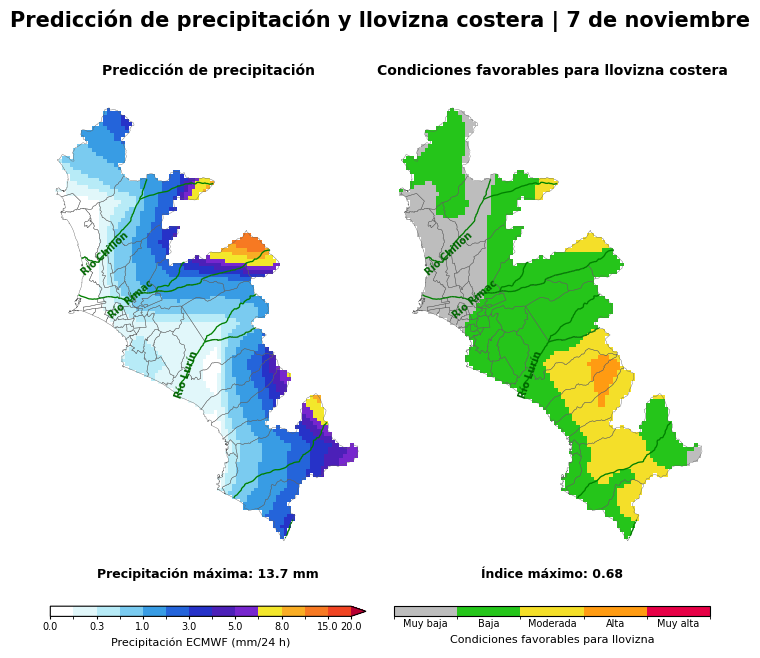

No se identificaron distritos con índice medio >= 0.60.

8 DE NOVIEMBRE


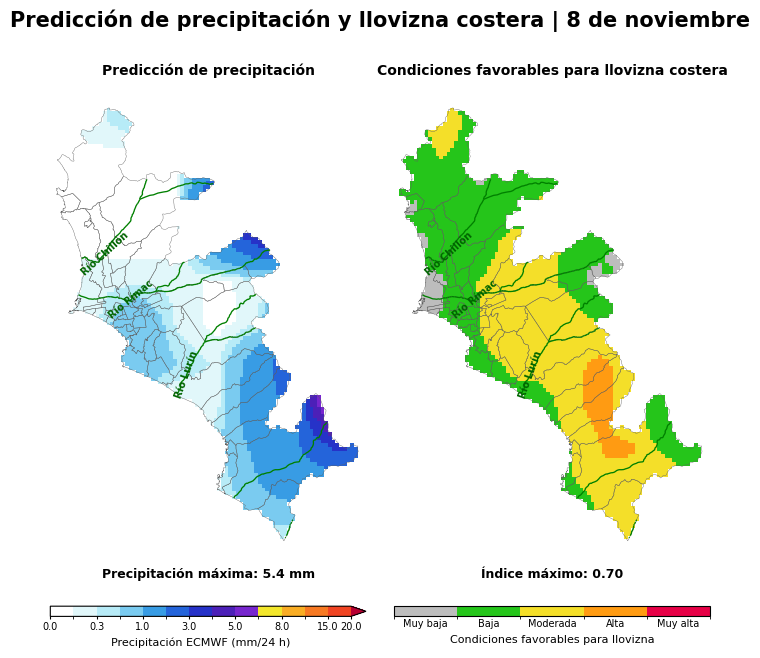

No se identificaron distritos con índice medio >= 0.60.

9 DE NOVIEMBRE


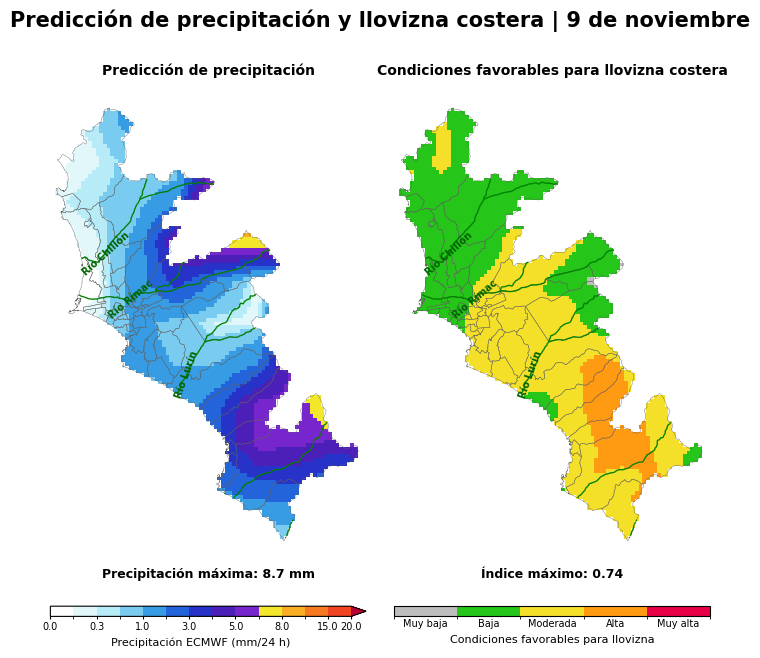


CONDICIONES MUY ALTA:
  Ningún distrito

CONDICIONES ALTA:
  PUNTA NEGRA                    Índice: 0.61 | Área >= 0.60: 61.7%
  SAN BARTOLO                    Índice: 0.60 | Área >= 0.60: 54.7%

10 DE NOVIEMBRE


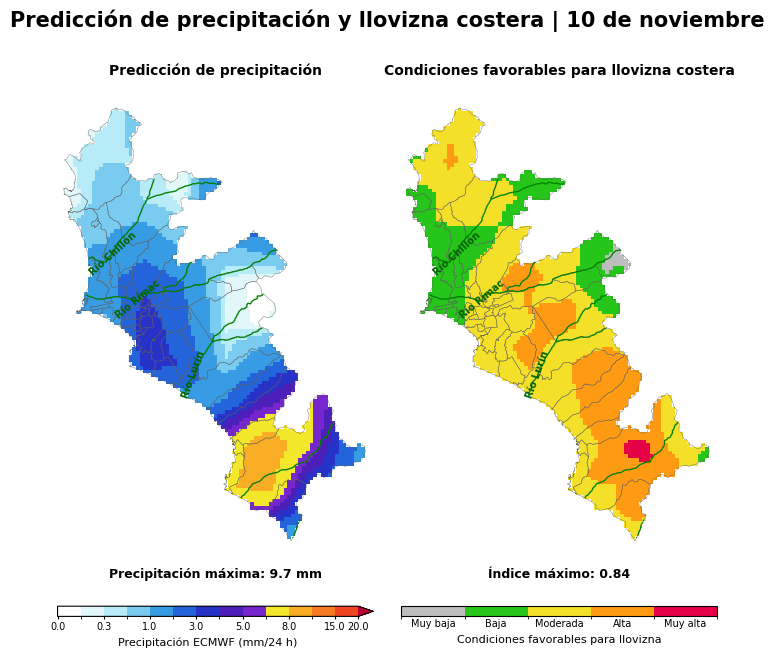


CONDICIONES MUY ALTA:
  Ningún distrito

CONDICIONES ALTA:
  PUNTA NEGRA                    Índice: 0.67 | Área >= 0.60: 82.0%
  PUNTA HERMOSA                  Índice: 0.65 | Área >= 0.60: 66.7%
  SAN BARTOLO                    Índice: 0.65 | Área >= 0.60: 71.7%
  CHILCA                         Índice: 0.64 | Área >= 0.60: 61.7%
  SANTA CRUZ DE FLORES           Índice: 0.64 | Área >= 0.60: 71.9%
  VILLA MARIA DEL TRIUNFO        Índice: 0.60 | Área >= 0.60: 53.0%
  LURIN                          Índice: 0.60 | Área >= 0.60: 42.3%

RESUMEN DE DISTRITOS


,Fecha,Distrito,Categoria,Indice_medio,Indice_maximo,Area_alta_pct,Area_muy_alta_pct
0,9 de noviembre,PUNTA NEGRA,Alta,0.61,0.72,61.65,0.00
1,9 de noviembre,SAN BARTOLO,Alta,0.60,0.69,54.72,0.00
2,10 de noviembre,PUNTA NEGRA,Alta,0.67,0.76,81.95,0.00
3,10 de noviembre,PUNTA HERMOSA,Alta,0.65,0.79,66.67,0.00
4,10 de noviembre,SAN BARTOLO,Alta,0.65,0.73,71.70,0.00
5,10 de noviembre,CHILCA,Alta,0.64,0.84,61.73,7.41
6,10 de noviembre,SANTA CRUZ DE FLORES,Alta,0.64,0.74,71.88,0.00
7,10 de noviembre,VILLA MARIA DEL TRIUNFO,Alta,0.60,0.65,53.03,0.00
8,10 de noviembre,LURIN,Alta,0.60,0.79,42.33,0.00



PROCESAMIENTO FINALIZADO
Figuras generadas: 5
Mapas por figura: 2
Resolución ECMWF: 0.1°
Malla de representación: 1 km
Archivos de salida guardados: ninguno


In [7]:

# ======================================================================
# PREDICCIÓN DE PRECIPITACIÓN Y CONDICIONES FAVORABLES PARA LLOVIZNA
# LIMA METROPOLITANA - ECMWF IFS 0.1°
# PRÓXIMOS 5 DÍAS
#
# GOOGLE COLAB - CÓDIGO COMPLETO
#
# - ECMWF IFS 0.1°
# - Precipitación acumulada en 24 horas
# - Humedad relativa a 2 m
# - Nubosidad baja
# - Viento a 10 m
# - Ascenso orográfico con DEM ASTER
# - Índice de condiciones favorables para llovizna
# - Una figura por día con dos mapas juntos
# - Ríos Chillón, Rímac y Lurín
# - Distritos con categorías Alta y Muy alta
# - Sin guardar resultados en Google Drive
#
# IMPORTANTE:
# El índice de llovizna es heurístico y no está calibrado.
# No equivale a una probabilidad de precipitación.
# ======================================================================


# ======================================================================
# 0. INSTALAR LIBRERÍAS
# ======================================================================

import sys
import subprocess

subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "ecmwf-opendata",
        "cfgrib",
        "eccodes",
        "xarray",
        "numpy",
        "pandas",
        "scipy",
        "geopandas",
        "rasterio",
        "matplotlib",
        "shapely",
        "pyproj"
    ],
    check=True
)


# ======================================================================
# 1. IMPORTACIONES
# ======================================================================

import gc
import os
import tempfile
import warnings
import unicodedata
import subprocess

from pathlib import Path
from datetime import timedelta
from zoneinfo import ZoneInfo

import numpy as np
import pandas as pd
import geopandas as gpd
import xarray as xr

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

from scipy.interpolate import RegularGridInterpolator
from scipy.ndimage import gaussian_filter

import rasterio
from rasterio.merge import merge
from rasterio.warp import (
    reproject,
    Resampling,
    transform as transformar_coords
)
from rasterio.transform import from_origin
from rasterio.features import rasterize

from shapely.geometry import Point
from shapely.ops import unary_union

from ecmwf.opendata import Client

from IPython.display import display
from google.colab import drive

warnings.filterwarnings(
    "ignore",
    category=FutureWarning
)

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "figure.facecolor": "white",
    "savefig.facecolor": "white"
})


# ======================================================================
# 2. CONFIGURACIÓN
# ======================================================================

drive.mount("/content/drive")

URL_REPO = (
    "https://github.com/Jorgellamocca/S2S-PER.git"
)

REPO = Path("/content/S2S-PER")
CARPETA_SHAPE = REPO / "shape"

RUTA_DEM = Path(
    "/content/drive/MyDrive/DEM_MINAM_LIMA_30m"
)

CRS_METRICO = "EPSG:32718"
CRS_GEOGRAFICO = "EPSG:4326"

TZ_PERU = ZoneInfo("America/Lima")

NUM_DIAS = 5

RESOLUCION_SALIDA = 1000

SIGMA_DEM_KM = 3.0

# Pasos ECMWF en horas.
# Se intentan intervalos de 3 horas.
PASOS = list(range(0, 121, 3))

# --------------------------------------------------------------
# DISEÑO CARTOGRÁFICO
# --------------------------------------------------------------

FIG_ANCHO = 10.5
FIG_ALTO = 6.8

SEPARACION_MAPAS = 0.08  # pulgadas

MARGEN_SUPERIOR = 1.0
MARGEN_INFERIOR = 1.15
MARGEN_LATERAL = 0.15

TAM_TITULO_GENERAL = 15
TAM_SUBTITULOS = 10
TAM_MAXIMOS = 9
TAM_ETIQUETAS_RIOS = 7
TAM_BARRAS = 7

COLOR_RIOS = "#008000"
COLOR_ETIQUETAS_RIOS = "#006400"

GROSOR_RIOS = 0.95
GROSOR_DISTRITOS = 0.28

MESES = [
    "enero", "febrero", "marzo",
    "abril", "mayo", "junio",
    "julio", "agosto", "septiembre",
    "octubre", "noviembre", "diciembre"
]

NOMBRES_RIOS = {
    "chillon": "Río Chillón",
    "rimac": "Río Rímac",
    "lurin": "Río Lurín"
}

REFERENCIAS_RIOS = {
    "chillon": (-77.07, -11.94),
    "rimac": (-76.99, -12.02),
    "lurin": (-76.88, -12.18)
}


# ======================================================================
# 3. FUNCIONES AUXILIARES
# ======================================================================

def normalizar_texto(texto):

    texto = str(texto).strip().lower()

    return "".join(
        c
        for c in unicodedata.normalize(
            "NFD", texto
        )
        if unicodedata.category(c) != "Mn"
    )


def buscar_archivo(carpeta, nombre):

    carpeta = Path(carpeta)

    encontrados = [
        p for p in carpeta.rglob("*")
        if p.is_file()
        and p.name.lower() == nombre.lower()
    ]

    if not encontrados:
        raise FileNotFoundError(
            f"No se encontró {nombre} en {carpeta}"
        )

    return encontrados[0]


def detectar_columna(gdf, candidatos):

    columnas = {
        normalizar_texto(c).upper(): c
        for c in gdf.columns
    }

    for candidato in candidatos:

        clave = normalizar_texto(
            candidato
        ).upper()

        if clave in columnas:
            return columnas[clave]

    return None


def fecha_espanol(fecha):

    return (
        f"{fecha.day} de "
        f"{MESES[fecha.month - 1]}"
    )


def pasos_horas(da):

    valores = np.asarray(
        da.step.values
    )

    if np.issubdtype(
        valores.dtype,
        np.timedelta64
    ):

        return (
            valores / np.timedelta64(1, "h")
        ).astype(int)

    return valores.astype(int)


def extraer_lineas(geom):

    if geom is None or geom.is_empty:
        return []

    if geom.geom_type == "LineString":
        return [geom]

    if geom.geom_type in (
        "MultiLineString",
        "GeometryCollection"
    ):

        lineas = []

        for parte in geom.geoms:
            lineas.extend(
                extraer_lineas(parte)
            )

        return lineas

    return []


# ======================================================================
# 4. CLONAR REPOSITORIO
# ======================================================================

print("\n" + "=" * 75)
print("PREPARACIÓN DE CARTOGRAFÍA")
print("=" * 75)

if not (REPO / ".git").exists():

    subprocess.run(
        [
            "git",
            "clone",
            "--depth",
            "1",
            URL_REPO,
            str(REPO)
        ],
        check=True
    )

else:

    resultado = subprocess.run(
        [
            "git",
            "-C",
            str(REPO),
            "pull",
            "--ff-only"
        ],
        capture_output=True,
        text=True
    )

    if resultado.returncode != 0:
        print(
            "Se utilizará la copia local."
        )


# ======================================================================
# 5. LEER SHAPEFILES
# ======================================================================

SHAPE_DISTRITOS = buscar_archivo(
    CARPETA_SHAPE,
    "Lima_metropolitana_distrito.shp"
)

SHAPE_RIOS = buscar_archivo(
    CARPETA_SHAPE,
    "rios_lima.shp"
)

distritos = gpd.read_file(
    SHAPE_DISTRITOS
)

rios = gpd.read_file(
    SHAPE_RIOS
)

if distritos.crs is None:
    raise ValueError(
        "El shapefile distrital no tiene CRS."
    )

if rios.crs is None:
    raise ValueError(
        "El shapefile de ríos no tiene CRS."
    )

col_distrito = detectar_columna(
    distritos,
    [
        "DISTRITO",
        "NOMBDIST",
        "NOMB_DIST",
        "NOM_DIST",
        "NOMBRE",
        "NOM_DIS"
    ]
)

if col_distrito is None:
    raise ValueError(
        "No se identificó el campo distrital."
    )

distritos = distritos.to_crs(
    CRS_METRICO
)

rios = rios.to_crs(
    CRS_METRICO
)

distritos = distritos[
    distritos.geometry.notna()
    &
    ~distritos.geometry.is_empty
].copy()

rios = rios[
    rios.geometry.notna()
    &
    ~rios.geometry.is_empty
].copy()

distritos["geometry"] = (
    distritos.geometry.make_valid()
)

distritos["DISTRITO"] = (
    distritos[col_distrito]
    .astype(str)
    .str.strip()
)

distritos = distritos.dissolve(
    by="DISTRITO",
    as_index=False
).reset_index(drop=True)

print(
    "Distritos:",
    len(distritos)
)

print(
    "Tramos de ríos:",
    len(rios)
)


# ======================================================================
# 6. IDENTIFICAR RÍOS
# ======================================================================

rios_mapa = rios.copy()

campo_rio = detectar_columna(
    rios_mapa,
    [
        "NOMBRE",
        "NOM_RIO",
        "RIO",
        "NOMBRE_RIO",
        "NOM_RIOS",
        "NAME"
    ]
)

if campo_rio is None:

    for columna in rios_mapa.columns:

        if columna == "geometry":
            continue

        try:

            valores = (
                rios_mapa[columna]
                .astype(str)
                .apply(normalizar_texto)
            )

            if valores.str.contains(
                "chillon|rimac|lurin",
                regex=True
            ).any():

                campo_rio = columna
                break

        except Exception:
            continue


geometrias_rios = {}

if campo_rio is not None:

    rios_mapa["_nombre"] = (
        rios_mapa[campo_rio]
        .astype(str)
        .apply(normalizar_texto)
    )

    for clave in NOMBRES_RIOS:

        seleccion = rios_mapa[
            rios_mapa["_nombre"].str.contains(
                clave,
                regex=False,
                na=False
            )
        ]

        lineas = []

        for geom in seleccion.geometry:

            lineas.extend(
                extraer_lineas(geom)
            )

        if lineas:
            geometrias_rios[clave] = lineas


referencias = gpd.GeoDataFrame(
    {
        "rio": list(
            REFERENCIAS_RIOS.keys()
        )
    },
    geometry=[
        Point(lon, lat)
        for lon, lat in REFERENCIAS_RIOS.values()
    ],
    crs=CRS_GEOGRAFICO
).to_crs(
    CRS_METRICO
)

referencias_utm = dict(
    zip(
        referencias["rio"],
        referencias.geometry
    )
)


for clave in NOMBRES_RIOS:

    if clave in geometrias_rios:
        continue

    referencia = referencias_utm[clave]

    candidatos = []

    for geom in rios_mapa.geometry:

        for linea in extraer_lineas(geom):

            distancia = linea.distance(
                referencia
            )

            if distancia <= 3000:

                candidatos.append(
                    (distancia, linea)
                )

    if candidatos:

        candidatos.sort(
            key=lambda elemento: elemento[0]
        )

        geometrias_rios[clave] = [
            candidatos[0][1]
        ]


def posicion_etiqueta_rio(clave):

    lineas = geometrias_rios.get(
        clave, []
    )

    if not lineas:
        return None

    referencia = referencias_utm[clave]

    linea = min(
        lineas,
        key=lambda g: g.distance(
            referencia
        )
    )

    if linea.length <= 0:
        return None

    distancia = linea.project(
        referencia
    )

    distancia = np.clip(
        distancia,
        linea.length * 0.15,
        linea.length * 0.85
    )

    punto = linea.interpolate(
        distancia
    )

    delta = min(
        700,
        max(30, linea.length * 0.08)
    )

    p1 = linea.interpolate(
        max(0, distancia - delta)
    )

    p2 = linea.interpolate(
        min(linea.length, distancia + delta)
    )

    angulo = np.degrees(
        np.arctan2(
            p2.y - p1.y,
            p2.x - p1.x
        )
    )

    if angulo > 90:
        angulo -= 180

    if angulo < -90:
        angulo += 180

    return punto.x, punto.y, angulo


# ======================================================================
# 7. DOMINIO UTM
# ======================================================================

xmin, ymin, xmax, ymax = (
    distritos.total_bounds
)

MARGEN = 4000
R = RESOLUCION_SALIDA

xmin = np.floor(
    (xmin - MARGEN) / R
) * R

ymin = np.floor(
    (ymin - MARGEN) / R
) * R

xmax = np.ceil(
    (xmax + MARGEN) / R
) * R

ymax = np.ceil(
    (ymax + MARGEN) / R
) * R

NX = int(
    round((xmax - xmin) / R)
)

NY = int(
    round((ymax - ymin) / R)
)

transform_salida = from_origin(
    xmin, ymax, R, R
)

x = xmin + (
    np.arange(NX) + 0.5
) * R

y = ymax - (
    np.arange(NY) + 0.5
) * R

XX, YY = np.meshgrid(x, y)

print(
    "Malla de representación:",
    NX, "x", NY
)


# ======================================================================
# 8. PROCESAR DEM ASTER
# ======================================================================

print("\n" + "=" * 75)
print("PROCESAMIENTO DEM ASTER")
print("=" * 75)

ARCHIVOS_DEM = [
    "ASTGTM_S12W077_dem.tif",
    "ASTGTM_S12W078_dem.tif",
    "ASTGTM_S13W077_dem.tif",
    "ASTGTM_S13W078_dem.tif"
]

fuentes = []

for nombre in ARCHIVOS_DEM:

    ruta = RUTA_DEM / nombre

    if not ruta.exists():
        raise FileNotFoundError(ruta)

    fuentes.append(
        rasterio.open(ruta)
    )

try:

    crs_dem = fuentes[0].crs

    if crs_dem is None:
        raise ValueError("DEM sin CRS.")

    if any(
        f.crs != crs_dem
        for f in fuentes
    ):
        raise ValueError(
            "Los DEM tienen CRS diferentes."
        )

    mosaico, trans_mosaico = merge(
        fuentes,
        masked=True
    )

finally:

    for fuente in fuentes:
        fuente.close()


banda = mosaico[0]

if np.ma.isMaskedArray(banda):

    dem_origen = banda.astype(
        np.float32
    ).filled(np.nan)

else:

    dem_origen = np.asarray(
        banda,
        dtype=np.float32
    )


DEM = np.full(
    (NY, NX),
    np.nan,
    dtype=np.float32
)

reproject(
    source=dem_origen,
    destination=DEM,
    src_transform=trans_mosaico,
    src_crs=crs_dem,
    src_nodata=np.nan,
    dst_transform=transform_salida,
    dst_crs=CRS_METRICO,
    dst_nodata=np.nan,
    resampling=Resampling.average
)

cobertura_dem = np.isfinite(DEM)

if not cobertura_dem.any():
    raise RuntimeError(
        "El DEM no cubre el dominio."
    )

sigma = SIGMA_DEM_KM * 1000 / R

numerador = gaussian_filter(
    np.where(cobertura_dem, DEM, 0),
    sigma
)

denominador = gaussian_filter(
    cobertura_dem.astype(float),
    sigma
)

DEM_SUAVE = np.divide(
    numerador,
    denominador,
    out=np.full_like(numerador, np.nan),
    where=denominador > 0.05
)

# Relleno auxiliar solo para calcular gradientes.
# No se usa para representar datos fuera de cobertura.
from scipy.ndimage import distance_transform_edt

invalidos = ~np.isfinite(DEM_SUAVE)

if invalidos.any():

    indices = distance_transform_edt(
        invalidos,
        return_distances=False,
        return_indices=True
    )

    dem_aux = DEM_SUAVE[
        tuple(indices)
    ]

else:

    dem_aux = DEM_SUAVE.copy()


grad_fila, dh_dx = np.gradient(
    dem_aux,
    R,
    R
)

dh_dy = -grad_fila

print(
    "Cobertura DEM:",
    f"{100 * cobertura_dem.mean():.1f}%"
)


# ======================================================================
# 9. CONSULTAR ECMWF IFS
# ======================================================================

print("\n" + "=" * 75)
print("CONSULTA ECMWF IFS")
print("=" * 75)

client = Client(
    source="ecmwf",
    model="ifs",
    resol="0p1"
)

candidatas = []

for hora in [0, 12]:

    try:

        ultima = client.latest(
            time=hora,
            stream="oper",
            type="fc",
            levtype="sfc",
            step=120,
            param="tp"
        )

        fecha = pd.Timestamp(ultima)

        if fecha.tzinfo is None:
            fecha = fecha.tz_localize("UTC")
        else:
            fecha = fecha.tz_convert("UTC")

        candidatas.append(fecha)

    except Exception as error:

        print(
            f"Ciclo {hora:02d} UTC:",
            str(error)[:100]
        )


if not candidatas:
    raise RuntimeError(
        "No se encontró una corrida ECMWF disponible."
    )

INICIO = max(candidatas)

FECHA = INICIO.strftime("%Y-%m-%d")
HORA = INICIO.hour

print("Inicialización:", INICIO)


# ======================================================================
# 10. DESCARGAR VARIABLES ECMWF
# ======================================================================

VARIABLES = {
    "tp": "tp",
    "2t": "t2m",
    "2d": "d2m",
    "10u": "u10",
    "10v": "v10",
    "lcc": "lcc"
}

datos = {}


def descargar_variable(
    parametro,
    nombre,
    carpeta_temporal
):

    ruta = (
        Path(carpeta_temporal)
        /
        f"{nombre}.grib2"
    )

    client.retrieve(
        date=FECHA,
        time=HORA,
        stream="oper",
        type="fc",
        levtype="sfc",
        step=PASOS,
        param=parametro,
        target=str(ruta)
    )

    ds = xr.open_dataset(
        ruta,
        engine="cfgrib",
        backend_kwargs={
            "indexpath": ""
        }
    )

    try:

        if nombre in ds.data_vars:
            da = ds[nombre]

        elif parametro in ds.data_vars:
            da = ds[parametro]

        elif len(ds.data_vars) == 1:
            da = ds[
                list(ds.data_vars)[0]
            ]

        else:
            raise ValueError(
                "Variable GRIB no identificada."
            )

        da = da.load()

    finally:
        ds.close()


    if float(da.longitude.max()) > 180:

        da = da.assign_coords(
            longitude=(
                (da.longitude + 180) % 360
            ) - 180
        )

    da = da.sortby(
        "latitude"
    ).sortby(
        "longitude"
    )

    da = da.sel(
        latitude=slice(-14.5, -10.5),
        longitude=slice(-79.0, -75.0)
    )

    return da


with tempfile.TemporaryDirectory() as tmp:

    for parametro, nombre in VARIABLES.items():

        print("Descargando:", parametro)

        try:

            datos[parametro] = descargar_variable(
                parametro,
                nombre,
                tmp
            )

            print(
                "OK:",
                datos[parametro].shape
            )

        except Exception as error:

            print(
                "No disponible:",
                parametro,
                str(error)[:150]
            )


if "tp" not in datos:
    raise RuntimeError(
        "No se descargó la precipitación ECMWF."
    )


# ======================================================================
# 11. INTERPOLACIÓN ECMWF A MALLA DE 1 KM
# ======================================================================

lon_lista, lat_lista = transformar_coords(
    CRS_METRICO,
    CRS_GEOGRAFICO,
    XX.ravel().tolist(),
    YY.ravel().tolist()
)

LON2D = np.asarray(lon_lista).reshape(
    NY, NX
)

LAT2D = np.asarray(lat_lista).reshape(
    NY, NX
)

puntos = np.column_stack(
    [
        LAT2D.ravel(),
        LON2D.ravel()
    ]
)


def interpolar_ecmwf(da):

    lat = np.asarray(
        da.latitude.values,
        dtype=float
    )

    lon = np.asarray(
        da.longitude.values,
        dtype=float
    )

    campos = []

    for paso in da.step.values:

        campo = da.sel(
            step=paso
        ).values

        interpolador = RegularGridInterpolator(
            (lat, lon),
            campo,
            method="linear",
            bounds_error=False,
            fill_value=np.nan
        )

        campos.append(
            interpolador(puntos).reshape(
                NY, NX
            )
        )

    return np.asarray(
        campos,
        dtype=np.float32
    )


grillas = {}

for parametro, da in datos.items():

    print("Interpolando:", parametro)

    grillas[parametro] = interpolar_ecmwf(da)


# ======================================================================
# 12. HUMEDAD RELATIVA
# ======================================================================

RH = None

if "2t" in grillas and "2d" in grillas:

    pasos_t = pasos_horas(datos["2t"])
    pasos_td = pasos_horas(datos["2d"])

    if np.array_equal(pasos_t, pasos_td):

        T = grillas["2t"] - 273.15
        TD = grillas["2d"] - 273.15

        es = 6.112 * np.exp(
            17.67 * T / (T + 243.5)
        )

        e = 6.112 * np.exp(
            17.67 * TD / (TD + 243.5)
        )

        RH = np.clip(
            100 * e / es,
            0, 100
        )


# ======================================================================
# 13. ASCENSO OROGRÁFICO
# ======================================================================

W_ORO = None

if "10u" in grillas and "10v" in grillas:

    pasos_u = pasos_horas(datos["10u"])
    pasos_v = pasos_horas(datos["10v"])

    if np.array_equal(pasos_u, pasos_v):

        U = grillas["10u"]
        V = grillas["10v"]

        W_ORO = (
            U * dh_dx[None, :, :]
            +
            V * dh_dy[None, :, :]
        )

        W_ORO[
            :, ~cobertura_dem
        ] = np.nan


# ======================================================================
# 14. NUBOSIDAD BAJA
# ======================================================================

LCC = None

if "lcc" in grillas:

    LCC = grillas["lcc"].copy()

    if np.nanmax(LCC) > 1.5:
        LCC /= 100

    LCC = np.clip(
        LCC,
        0, 1
    )


# ======================================================================
# 15. ÍNDICE DE CONDICIONES FAVORABLES PARA LLOVIZNA
# ======================================================================

INDICE = None
PASOS_INDICE = None

if (
    RH is not None
    and W_ORO is not None
    and LCC is not None
):

    PASOS_INDICE = sorted(
        set(pasos_horas(datos["2t"]))
        &
        set(pasos_horas(datos["2d"]))
        &
        set(pasos_horas(datos["10u"]))
        &
        set(pasos_horas(datos["10v"]))
        &
        set(pasos_horas(datos["lcc"]))
    )


    def seleccionar_pasos(
        array,
        pasos_originales
    ):

        lista = list(pasos_originales)

        indices = [
            lista.index(p)
            for p in PASOS_INDICE
        ]

        return array[indices]


    rh = seleccionar_pasos(
        RH,
        pasos_horas(datos["2t"])
    )

    nube = seleccionar_pasos(
        LCC,
        pasos_horas(datos["lcc"])
    )

    w = seleccionar_pasos(
        W_ORO,
        pasos_horas(datos["10u"])
    )

    F_HR = np.clip(
        (rh - 80) / 18,
        0, 1
    )

    F_NUBE = np.clip(
        (nube - 0.4) / 0.6,
        0, 1
    )

    F_ORO = np.clip(
        np.maximum(w, 0) / 0.15,
        0, 1
    )

    horas = np.array([
        (
            INICIO
            +
            pd.Timedelta(hours=int(p))
        ).tz_convert(TZ_PERU).hour

        for p in PASOS_INDICE
    ])

    F_DIURNO = (
        0.5
        +
        0.5 * np.cos(
            2 * np.pi * (horas - 4) / 24
        )
    )[:, None, None]

    INDICE = (
        0.35 * F_HR
        +
        0.35 * F_NUBE
        +
        0.20 * F_ORO
        +
        0.10 * F_DIURNO
    )

    INDICE = np.clip(
        INDICE,
        0, 1
    )

    INDICE[
        :, ~cobertura_dem
    ] = np.nan

else:

    raise RuntimeError(
        "No se pudo calcular el índice. "
        "Revisa la disponibilidad de 2t, 2d, 10u, 10v y lcc."
    )


# ======================================================================
# 16. ACUMULADOS DIARIOS
# ======================================================================

pasos_tp = pasos_horas(
    datos["tp"]
)

TP = grillas["tp"] * 1000

PP_DIARIA = []
INDICE_DIARIO = []
PERIODOS = []

for dia in range(NUM_DIAS):

    paso_i = dia * 24
    paso_f = (dia + 1) * 24

    if paso_f not in pasos_tp:
        raise RuntimeError(
            f"Falta el paso {paso_f} h."
        )

    idx_f = list(pasos_tp).index(
        paso_f
    )

    if paso_i in pasos_tp:

        idx_i = list(pasos_tp).index(
            paso_i
        )

        inicial = TP[idx_i]

    elif paso_i == 0:

        inicial = np.zeros_like(
            TP[idx_f]
        )

    else:

        raise RuntimeError(
            f"Falta el paso {paso_i} h."
        )

    diario = TP[idx_f] - inicial

    diario = np.where(
        diario >= -0.001,
        np.maximum(diario, 0),
        np.nan
    )

    PP_DIARIA.append(diario)

    indices = [
        i
        for i, paso in enumerate(
            PASOS_INDICE
        )
        if paso_i < paso <= paso_f
    ]

    if indices:

        INDICE_DIARIO.append(
            np.nanmean(
                INDICE[indices],
                axis=0
            )
        )

    else:

        INDICE_DIARIO.append(
            np.full(
                (NY, NX),
                np.nan
            )
        )

    inicio_local = (
        INICIO
        +
        pd.Timedelta(hours=paso_i)
    ).tz_convert(TZ_PERU)

    fin_local = (
        INICIO
        +
        pd.Timedelta(hours=paso_f)
    ).tz_convert(TZ_PERU)

    PERIODOS.append(
        (inicio_local, fin_local)
    )


PP_DIARIA = np.asarray(PP_DIARIA)
INDICE_DIARIO = np.asarray(INDICE_DIARIO)


# ======================================================================
# 17. MÁSCARA DISTRITAL
# ======================================================================

MASCARA_LIMA = rasterize(
    [
        (geom, 1)
        for geom in distritos.geometry
    ],
    out_shape=(NY, NX),
    transform=transform_salida,
    fill=0,
    dtype="uint8"
).astype(bool)

ID_DISTRITO = rasterize(
    [
        (geom, i + 1)
        for i, geom in enumerate(
            distritos.geometry
        )
    ],
    out_shape=(NY, NX),
    transform=transform_salida,
    fill=0,
    dtype="int32"
)

PP_LIMA = np.where(
    MASCARA_LIMA[None, :, :],
    PP_DIARIA,
    np.nan
)

INDICE_LIMA = np.where(
    MASCARA_LIMA[None, :, :],
    INDICE_DIARIO,
    np.nan
)


# ======================================================================
# 18. PALETA DE PRECIPITACIÓN
# ======================================================================

NIVELES_PP = [
    0, 0.1, 0.3, 0.5, 1,
    2, 3, 4, 5, 6,
    8, 10, 15, 20
]

COLORES_PP = [
    "#FFFFFF",
    "#E1F7FA",
    "#B7EBF7",
    "#7ACBF0",
    "#389CE4",
    "#2464DA",
    "#2632C8",
    "#4C20B8",
    "#7726CE",
    "#F3E72B",
    "#F9AD24",
    "#F77922",
    "#F04422"
]

cmap_pp = mcolors.ListedColormap(
    COLORES_PP
)

norm_pp = mcolors.BoundaryNorm(
    NIVELES_PP,
    cmap_pp.N
)

cmap_pp.set_over("#B80032")
cmap_pp.set_bad((1, 1, 1, 0))


# ======================================================================
# 19. PALETA DE LLOVIZNA
# ======================================================================

NIVELES_LLOVIZNA = [
    0, 0.2, 0.4, 0.6, 0.8, 1.000001
]

COLORES_LLOVIZNA = [
    "#BDBDBD",
    "#25C51A",
    "#F4DF29",
    "#FF9B12",
    "#E60046"
]

CATEGORIAS_LLOVIZNA = [
    "Muy baja",
    "Baja",
    "Moderada",
    "Alta",
    "Muy alta"
]

cmap_llovizna = mcolors.ListedColormap(
    COLORES_LLOVIZNA
)

norm_llovizna = mcolors.BoundaryNorm(
    NIVELES_LLOVIZNA,
    cmap_llovizna.N
)

cmap_llovizna.set_bad((1, 1, 1, 0))


# ======================================================================
# 20. DISTRIBUCIÓN AUTOMÁTICA DE LOS DOS MAPAS
# ======================================================================

def calcular_distribucion():

    # EPSG:32718 - unidades en metros
    ancho_geo = xmax - xmin
    alto_geo = ymax - ymin

    relacion = ancho_geo / alto_geo

    alto_disponible = (
        FIG_ALTO
        - MARGEN_SUPERIOR
        - MARGEN_INFERIOR
    )

    ancho_maximo = (
        FIG_ANCHO
        - 2 * MARGEN_LATERAL
        - SEPARACION_MAPAS
    ) / 2

    alto_mapa = min(
        alto_disponible,
        ancho_maximo / relacion
    )

    ancho_mapa = alto_mapa * relacion

    ancho_total = (
        2 * ancho_mapa
        + SEPARACION_MAPAS
    )

    x_inicio = (
        FIG_ANCHO - ancho_total
    ) / 2

    y_inicio = (
        MARGEN_INFERIOR
        +
        (alto_disponible - alto_mapa) / 2
    )

    pos_pp = [
        x_inicio / FIG_ANCHO,
        y_inicio / FIG_ALTO,
        ancho_mapa / FIG_ANCHO,
        alto_mapa / FIG_ALTO
    ]

    pos_ll = [
        (
            x_inicio
            + ancho_mapa
            + SEPARACION_MAPAS
        ) / FIG_ANCHO,
        y_inicio / FIG_ALTO,
        ancho_mapa / FIG_ANCHO,
        alto_mapa / FIG_ALTO
    ]

    return pos_pp, pos_ll


# ======================================================================
# 21. DIBUJAR CARTOGRAFÍA
# ======================================================================

def dibujar_cartografia(ax):

    distritos.boundary.plot(
        ax=ax,
        color="#606060",
        linewidth=GROSOR_DISTRITOS,
        zorder=10
    )

    rios_mapa.plot(
        ax=ax,
        color=COLOR_RIOS,
        linewidth=GROSOR_RIOS,
        zorder=20
    )

    for clave, nombre in NOMBRES_RIOS.items():

        posicion = posicion_etiqueta_rio(clave)

        if posicion is None:
            continue

        x_rio, y_rio, angulo = posicion

        ax.text(
            x_rio,
            y_rio,
            nombre,
            fontsize=TAM_ETIQUETAS_RIOS,
            fontweight="bold",
            color=COLOR_ETIQUETAS_RIOS,
            ha="center",
            va="center",
            rotation=angulo,
            rotation_mode="anchor",
            zorder=30,
            clip_on=False,
            bbox=None
        )

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)

    ax.set_aspect(
        "equal",
        adjustable="box"
    )

    ax.axis("off")


# ======================================================================
# 22. MÁXIMOS
# ======================================================================

def calcular_maximo(campo):

    validos = (
        MASCARA_LIMA
        &
        np.isfinite(campo)
    )

    if not np.any(validos):
        return np.nan

    return float(
        np.max(campo[validos])
    )


# ======================================================================
# 23. GENERAR FIGURA DIARIA
# ======================================================================

def generar_figura_diaria(dia):

    campo_pp = PP_LIMA[dia]
    campo_ll = INDICE_LIMA[dia]

    inicio, fin = PERIODOS[dia]
    fecha = fecha_espanol(fin)

    pos_pp, pos_ll = calcular_distribucion()

    fig = plt.figure(
        figsize=(FIG_ANCHO, FIG_ALTO),
        facecolor="white"
    )

    ax_pp = fig.add_axes(pos_pp)
    ax_ll = fig.add_axes(pos_ll)

    # --------------------------------------------------------------
    # TÍTULO GENERAL
    # --------------------------------------------------------------

    fig.text(
        0.5,
        0.975,
        (
            "Predicción de precipitación y "
            f"llovizna costera | {fecha}"
        ),
        ha="center",
        va="top",
        fontsize=TAM_TITULO_GENERAL,
        fontweight="bold"
    )

    # --------------------------------------------------------------
    # MAPA PRECIPITACIÓN
    # --------------------------------------------------------------

    m_pp = ax_pp.pcolormesh(
        XX,
        YY,
        campo_pp,
        cmap=cmap_pp,
        norm=norm_pp,
        shading="auto",
        rasterized=True,
        zorder=2
    )

    dibujar_cartografia(ax_pp)

    # --------------------------------------------------------------
    # MAPA LLOVIZNA
    # --------------------------------------------------------------

    m_ll = ax_ll.pcolormesh(
        XX,
        YY,
        campo_ll,
        cmap=cmap_llovizna,
        norm=norm_llovizna,
        shading="auto",
        rasterized=True,
        zorder=2
    )

    dibujar_cartografia(ax_ll)

    centro_pp = pos_pp[0] + pos_pp[2] / 2
    centro_ll = pos_ll[0] + pos_ll[2] / 2

    # --------------------------------------------------------------
    # SUBTÍTULOS ALINEADOS
    # --------------------------------------------------------------

    y_titulo = 0.885

    fig.text(
        centro_pp,
        y_titulo,
        "Predicción de precipitación",
        ha="center",
        va="center",
        fontsize=TAM_SUBTITULOS,
        fontweight="bold"
    )

    fig.text(
        centro_ll,
        y_titulo,
        "Condiciones favorables para llovizna costera",
        ha="center",
        va="center",
        fontsize=TAM_SUBTITULOS,
        fontweight="bold"
    )

    # --------------------------------------------------------------
    # MÁXIMOS
    # --------------------------------------------------------------

    max_pp = calcular_maximo(campo_pp)
    max_ll = calcular_maximo(campo_ll)

    fig.text(
        centro_pp,
        0.145,
        f"Precipitación máxima: {max_pp:.1f} mm",
        ha="center",
        va="center",
        fontsize=TAM_MAXIMOS,
        fontweight="bold"
    )

    fig.text(
        centro_ll,
        0.145,
        f"Índice máximo: {max_ll:.2f}",
        ha="center",
        va="center",
        fontsize=TAM_MAXIMOS,
        fontweight="bold"
    )

    # --------------------------------------------------------------
    # BARRAS PEQUEÑAS
    # --------------------------------------------------------------

    ancho_barra_pp = pos_pp[2] * 0.94
    ancho_barra_ll = pos_ll[2] * 0.94

    cax_pp = fig.add_axes([
        centro_pp - ancho_barra_pp / 2,
        0.083,
        ancho_barra_pp,
        0.015
    ])

    cax_ll = fig.add_axes([
        centro_ll - ancho_barra_ll / 2,
        0.083,
        ancho_barra_ll,
        0.015
    ])

    cb_pp = fig.colorbar(
        m_pp,
        cax=cax_pp,
        orientation="horizontal",
        extend="max",
        ticks=[0, 0.3, 1, 3, 5, 8, 15, 20]
    )

    cb_pp.ax.tick_params(
        labelsize=TAM_BARRAS,
        length=2,
        pad=2
    )

    cb_pp.set_label(
        "Precipitación ECMWF (mm/24 h)",
        fontsize=8,
        labelpad=4
    )

    cb_ll = fig.colorbar(
        m_ll,
        cax=cax_ll,
        orientation="horizontal",
        ticks=[0.1, 0.3, 0.5, 0.7, 0.9],
        spacing="uniform"
    )

    cb_ll.ax.set_xticklabels(
        CATEGORIAS_LLOVIZNA
    )

    cb_ll.ax.tick_params(
        labelsize=TAM_BARRAS,
        length=0,
        pad=2
    )

    cb_ll.set_label(
        "Condiciones favorables para llovizna",
        fontsize=8,
        labelpad=4
    )

    plt.show()
    plt.close(fig)


# ======================================================================
# 24. DISTRITOS CON CONDICIONES ALTAS Y MUY ALTAS
# ======================================================================

def obtener_distritos_altos(campo):

    resultados = []

    for i, fila in distritos.iterrows():

        mascara = ID_DISTRITO == i + 1

        valores = campo[mascara]
        valores = valores[np.isfinite(valores)]

        if valores.size == 0:
            continue

        indice_medio = float(
            np.mean(valores)
        )

        indice_maximo = float(
            np.max(valores)
        )

        area_alta = float(
            100 * np.mean(valores >= 0.60)
        )

        area_muy_alta = float(
            100 * np.mean(valores >= 0.80)
        )

        if indice_medio >= 0.80:
            categoria = "Muy alta"

        elif indice_medio >= 0.60:
            categoria = "Alta"

        else:
            continue

        resultados.append({
            "Distrito": fila["DISTRITO"],
            "Categoria": categoria,
            "Indice_medio": indice_medio,
            "Indice_maximo": indice_maximo,
            "Area_alta_pct": area_alta,
            "Area_muy_alta_pct": area_muy_alta
        })

    tabla = pd.DataFrame(resultados)

    if not tabla.empty:

        tabla = tabla.sort_values(
            "Indice_medio",
            ascending=False
        ).reset_index(drop=True)

    return tabla


# ======================================================================
# 25. GENERAR LOS CINCO DÍAS
# ======================================================================

TABLAS_DIARIAS = []

for dia in range(NUM_DIAS):

    fecha = fecha_espanol(
        PERIODOS[dia][1]
    )

    print("\n" + "=" * 85)
    print(fecha.upper())
    print("=" * 85)

    generar_figura_diaria(dia)

    tabla = obtener_distritos_altos(
        INDICE_LIMA[dia]
    )

    tabla["Fecha"] = fecha

    TABLAS_DIARIAS.append(tabla)

    if tabla.empty:

        print(
            "No se identificaron distritos "
            "con índice medio >= 0.60."
        )

    else:

        for categoria in ["Muy alta", "Alta"]:

            seleccion = tabla[
                tabla["Categoria"] == categoria
            ]

            print(
                f"\nCONDICIONES {categoria.upper()}:"
            )

            if seleccion.empty:
                print("  Ningún distrito")

            else:

                for fila in seleccion.itertuples():

                    print(
                        f"  {fila.Distrito:<30}"
                        f" Índice: {fila.Indice_medio:.2f}"
                        f" | Área >= 0.60: "
                        f"{fila.Area_alta_pct:.1f}%"
                    )


# ======================================================================
# 26. RESUMEN FINAL
# ======================================================================

TABLA_FINAL = pd.concat(
    TABLAS_DIARIAS,
    ignore_index=True
)

print("\n" + "=" * 85)
print("RESUMEN DE DISTRITOS")
print("=" * 85)

if not TABLA_FINAL.empty:

    display(
        TABLA_FINAL.round(2)
    )

else:

    print(
        "No se identificaron distritos "
        "en categorías Alta o Muy alta."
    )

gc.collect()

print("\n" + "=" * 85)
print("PROCESAMIENTO FINALIZADO")
print("=" * 85)

print("Figuras generadas:", NUM_DIAS)
print("Mapas por figura: 2")
print("Resolución ECMWF: 0.1°")
print("Malla de representación: 1 km")
print("Archivos de salida guardados: ninguno")


In [3]:

# ======================================================================
# PRONÓSTICO DE PRECIPITACIÓN - LIMA METROPOLITANA
# ECMWF IFS 0.1° - 5 PERIODOS DE 24 HORAS
#
# VERSIÓN SIN SUAVIZADO ARTIFICIAL
# - Grilla nativa ECMWF (sin interpolación bilineal)
# - Barra de colores cercana a la tabla
# - Tabla con filas y letras proporcionadas
# - Solo límites de Lima_distritos.shp
# - Ríos Chillón, Rímac y Lurín
# - 5 PNG a 300 dpi + ZIP
# ======================================================================

import sys
import subprocess

subprocess.run(
    [
        sys.executable, "-m", "pip", "install", "-q",
        "ecmwf-opendata", "cfgrib", "eccodes",
        "xarray", "geopandas", "cartopy",
        "matplotlib", "shapely", "pyproj",
        "pandas", "rasterio"
    ],
    check=True
)

import os
import zipfile
import tempfile
import warnings
import unicodedata

from pathlib import Path
from zoneinfo import ZoneInfo

import numpy as np
import pandas as pd
import geopandas as gpd
import xarray as xr

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.ticker as mticker

from matplotlib.cm import ScalarMappable
from matplotlib.gridspec import GridSpec

from shapely.geometry import box
from shapely.ops import unary_union

from rasterio.features import rasterize
from rasterio.transform import from_bounds

from ecmwf.opendata import Client

import cartopy.crs as ccrs
import cartopy.feature as cfeature

from IPython.display import display
from google.colab import drive

warnings.filterwarnings("ignore", category=FutureWarning)


# ======================================================================
# 1. GOOGLE DRIVE Y CONFIGURACIÓN
# ======================================================================

drive.mount("/content/drive")

RUTA_SALIDA = Path(
    "/content/drive/MyDrive/PRONOSTICO_ECMWF_LIMA"
)
RUTA_SALIDA.mkdir(parents=True, exist_ok=True)

REPO = Path("/content/S2S-PER")
URL_REPO = "https://github.com/Jorgellamocca/S2S-PER.git"

TZ_PERU = ZoneInfo("America/Lima")

NUM_DIAS = 5
TOP_N = 5
DPI_SALIDA = 300

ANCHO_FIGURA = 12
ALTO_FIGURA = 14

MARGEN_LON = 0.045
MARGEN_LAT = 0.045

COLOR_OCEANO = "#DCEEF5"
COLOR_RIOS = "#075B90"
COLOR_BORDES = "#505050"

MESES = [
    "enero", "febrero", "marzo", "abril",
    "mayo", "junio", "julio", "agosto",
    "septiembre", "octubre", "noviembre",
    "diciembre"
]

POSICIONES_ETIQUETAS = {
    "Río Chillón": (-76.96, -11.84),
    "Río Rímac": (-76.90, -12.01),
    "Río Lurín": (-76.79, -12.20)
}


# ======================================================================
# 2. FUNCIONES
# ======================================================================

def normalizar_texto(texto):
    texto = str(texto).lower().strip()
    return "".join(
        c for c in unicodedata.normalize("NFD", texto)
        if unicodedata.category(c) != "Mn"
    )


def buscar_archivo(carpeta, nombre):
    encontrados = [
        p for p in carpeta.iterdir()
        if p.name.lower() == nombre.lower()
    ]
    if not encontrados:
        raise FileNotFoundError(
            f"No se encontró {nombre} en {carpeta}"
        )
    return encontrados[0]


def fecha_espanol(fecha):
    return f"{fecha.day} de {MESES[fecha.month - 1]}"


def formato_longitud(x, pos=None):
    return f"{abs(x):.2f}°{'O' if x < 0 else 'E'}"


def formato_latitud(y, pos=None):
    return f"{abs(y):.2f}°{'S' if y < 0 else 'N'}"


def ticks_coordenadas(minimo, maximo, paso=0.25):
    inicio = np.ceil(minimo / paso) * paso
    return np.arange(inicio, maximo + 0.0001, paso)


def bordes_grilla(coordenadas):
    c = np.asarray(coordenadas, dtype=float)
    medios = (c[:-1] + c[1:]) / 2
    primero = c[0] - (c[1] - c[0]) / 2
    ultimo = c[-1] + (c[-1] - c[-2]) / 2
    return np.concatenate([[primero], medios, [ultimo]])


# ======================================================================
# 3. CARTOGRAFÍA
# ======================================================================

print("ACTUALIZANDO CARTOGRAFÍA...")

if not (REPO / ".git").exists():
    subprocess.run(
        ["git", "clone", URL_REPO, str(REPO)],
        check=True
    )
else:
    resultado = subprocess.run(
        ["git", "-C", str(REPO), "pull", "--ff-only"],
        capture_output=True,
        text=True
    )
    if resultado.returncode != 0:
        print("Se utilizará la copia local del repositorio.")

CARPETA_SHAPE = REPO / "shape"

SHAPE_DISTRITOS = buscar_archivo(
    CARPETA_SHAPE, "Lima_distritos.shp"
)
SHAPE_RIOS = buscar_archivo(
    CARPETA_SHAPE, "rios_lima.shp"
)

gdf = gpd.read_file(SHAPE_DISTRITOS)

if gdf.crs is None:
    raise ValueError("El shapefile distrital no tiene CRS.")

gdf = gdf.to_crs("EPSG:4326")
gdf = gdf[
    gdf.geometry.notna() & ~gdf.geometry.is_empty
].copy()

gdf["geometry"] = gdf.geometry.make_valid()

columnas = {c.upper(): c for c in gdf.columns}

col_distrito = next(
    (
        columnas[c]
        for c in [
            "DISTRITO", "NOMBDIST",
            "NOMB_DIST", "NOM_DIST", "NOMBRE"
        ]
        if c in columnas
    ),
    None
)

if col_distrito is None:
    raise ValueError(
        f"No se encontró columna distrital: {gdf.columns.tolist()}"
    )

gdf["DISTRITO"] = (
    gdf[col_distrito].astype(str).str.strip()
)

gdf = gdf[
    ~gdf["DISTRITO"].str.upper().isin(["", "NAN", "NONE"])
].copy()

gdf = gdf.dissolve(
    by="DISTRITO", as_index=False
)

print("Distritos:", len(gdf))


# ======================================================================
# 4. RÍOS
# ======================================================================

rios = gpd.read_file(SHAPE_RIOS)

if rios.crs is None:
    raise ValueError("El shapefile de ríos no tiene CRS.")

rios = rios.to_crs("EPSG:4326")
rios = rios[
    rios.geometry.notna() & ~rios.geometry.is_empty
].copy()

rios["geometry"] = rios.geometry.make_valid()

col_rio = None

for columna in rios.columns:
    if columna == "geometry":
        continue

    valores = rios[columna].dropna().astype(str)

    if valores.apply(
        lambda x: any(
            n in normalizar_texto(x)
            for n in ["chillon", "rimac", "lurin"]
        )
    ).any():
        col_rio = columna
        break

rios_principales = {}

if col_rio is not None:
    rios["_nombre"] = rios[col_rio].apply(normalizar_texto)

    for clave, nombre in [
        ("chillon", "Río Chillón"),
        ("rimac", "Río Rímac"),
        ("lurin", "Río Lurín")
    ]:
        seleccion = rios[
            rios["_nombre"].str.contains(clave, na=False)
        ].copy()

        if not seleccion.empty:
            geometria = unary_union(
                seleccion.geometry.tolist()
            )
            rios_principales[nombre] = gpd.GeoDataFrame(
                {"nombre": [nombre]},
                geometry=[geometria],
                crs="EPSG:4326"
            )

print("Ríos:", list(rios_principales))


# ======================================================================
# 5. EXTENSIÓN
# ======================================================================

xmin, ymin, xmax, ymax = gdf.total_bounds

extent = [
    xmin - MARGEN_LON,
    xmax + MARGEN_LON,
    ymin - MARGEN_LAT,
    ymax + MARGEN_LAT
]

LON_MIN, LON_MAX, LAT_MIN, LAT_MAX = extent


# ======================================================================
# 6. CONSULTAR ECMWF
# ======================================================================

client = Client(
    source="ecmwf",
    model="ifs",
    resol="0p1"
)

candidatas = []

for hora in [0, 12]:
    try:
        ultima = client.latest(
            time=hora,
            stream="oper",
            type="fc",
            levtype="sfc",
            step=120,
            param="tp"
        )

        fecha = pd.Timestamp(ultima)

        if fecha.tzinfo is None:
            fecha = fecha.tz_localize("UTC")
        else:
            fecha = fecha.tz_convert("UTC")

        candidatas.append(fecha)

    except Exception as error:
        print(
            f"Ciclo {hora:02d} no disponible:",
            str(error)[:100]
        )

if not candidatas:
    raise RuntimeError("No hay corrida ECMWF disponible.")

inicio_utc = max(candidatas)

FECHA = inicio_utc.strftime("%Y-%m-%d")
HORA = inicio_utc.hour

print("Corrida ECMWF:", inicio_utc)


# ======================================================================
# 7. DESCARGAR GRIB
# ======================================================================

PASOS = [24, 48, 72, 96, 120]

temporal = tempfile.TemporaryDirectory()

GRIB = os.path.join(
    temporal.name, "ecmwf_ifs_tp_5dias.grib2"
)

client.retrieve(
    date=FECHA,
    time=HORA,
    stream="oper",
    type="fc",
    levtype="sfc",
    step=PASOS,
    param="tp",
    target=GRIB
)

print(
    "GRIB descargado:",
    round(os.path.getsize(GRIB) / 1024**2, 2),
    "MB"
)


# ======================================================================
# 8. LEER PRECIPITACIÓN
# ======================================================================

ds = xr.open_dataset(
    GRIB,
    engine="cfgrib",
    backend_kwargs={"indexpath": ""}
)

tp = ds["tp"]

if float(tp.longitude.max()) > 180:
    tp = tp.assign_coords(
        longitude=((tp.longitude + 180) % 360) - 180
    )

tp = tp.sortby("latitude").sortby("longitude")

tp = tp.sel(
    latitude=slice(LAT_MIN - 0.20, LAT_MAX + 0.20),
    longitude=slice(LON_MIN - 0.20, LON_MAX + 0.20)
)

lat = np.asarray(tp.latitude.values, dtype=float)
lon = np.asarray(tp.longitude.values, dtype=float)

if len(lat) < 2 or len(lon) < 2:
    raise ValueError("Grilla ECMWF insuficiente.")

inicio_utc = pd.Timestamp(tp.time.values)

if inicio_utc.tzinfo is None:
    inicio_utc = inicio_utc.tz_localize("UTC")
else:
    inicio_utc = inicio_utc.tz_convert("UTC")


# ======================================================================
# 9. ACUMULADOS DE 24 HORAS
# ======================================================================

pp_diaria = []
periodos = []

for i, paso_final in enumerate(PASOS):

    paso_inicial = i * 24

    final = (
        tp.sel(
            step=np.timedelta64(paso_final, "h")
        ).values * 1000.0
    )

    if i == 0:
        diario = final.copy()
    else:
        inicial = (
            tp.sel(
                step=np.timedelta64(paso_inicial, "h")
            ).values * 1000.0
        )
        diario = final - inicial

    diario = np.where(
        diario >= 0, diario, np.nan
    )

    pp_diaria.append(diario)

    fecha_inicio = (
        inicio_utc + pd.Timedelta(hours=paso_inicial)
    ).tz_convert(TZ_PERU)

    fecha_fin = (
        inicio_utc + pd.Timedelta(hours=paso_final)
    ).tz_convert(TZ_PERU)

    periodos.append({
        "inicio_peru": fecha_inicio,
        "fin_peru": fecha_fin
    })

pp = np.stack(pp_diaria, axis=0)


# ======================================================================
# 10. ESTADÍSTICAS DISTRITALES
# ======================================================================

lon_b = bordes_grilla(lon)
lat_b = bordes_grilla(lat)

celdas = []

for iy in range(len(lat)):
    for ix in range(len(lon)):
        celdas.append({
            "iy": iy,
            "ix": ix,
            "geometry": box(
                lon_b[ix], lat_b[iy],
                lon_b[ix + 1], lat_b[iy + 1]
            )
        })

grid = gpd.GeoDataFrame(
    celdas, geometry="geometry", crs="EPSG:4326"
)

CRS_AREA = "EPSG:6933"

inter = gpd.overlay(
    gdf.to_crs(CRS_AREA)[["DISTRITO", "geometry"]],
    grid.to_crs(CRS_AREA)[["iy", "ix", "geometry"]],
    how="intersection",
    keep_geom_type=False
)

inter["area_m2"] = inter.geometry.area
inter = inter[inter["area_m2"] > 0].copy()

resultados = []

for dia in range(NUM_DIAS):
    campo = pp[dia]

    for nombre, grupo in inter.groupby("DISTRITO"):
        iy = grupo["iy"].to_numpy(dtype=int)
        ix = grupo["ix"].to_numpy(dtype=int)

        valores = campo[iy, ix]
        areas = grupo["area_m2"].to_numpy(dtype=float)

        validos = (
            np.isfinite(valores)
            & np.isfinite(areas)
            & (areas > 0)
        )

        if not np.any(validos):
            continue

        media = np.average(
            valores[validos],
            weights=areas[validos]
        )

        resultados.append({
            "Dia": dia + 1,
            "Distrito": nombre,
            "PP_media_mm": float(media),
            "PP_max_mm": float(np.max(valores[validos])),
            "Cobertura_pct": float(
                100 * areas[validos].sum() / areas.sum()
            )
        })

tabla = pd.DataFrame(resultados)

tabla = tabla.sort_values(
    ["Dia", "PP_media_mm"],
    ascending=[True, False]
).reset_index(drop=True)

tabla["Ranking"] = (
    tabla.groupby("Dia").cumcount() + 1
)


# ======================================================================
# 11. MÁSCARA TIERRA/OCÉANO EN GRILLA NATIVA
# ======================================================================

land = cfeature.NaturalEarthFeature(
    "physical", "land", "10m"
)

dominio = box(
    LON_MIN - 0.1,
    LAT_MIN - 0.1,
    LON_MAX + 0.1,
    LAT_MAX + 0.1
)

geometrias = []

for geom in land.geometries():
    if geom.intersects(dominio):
        recorte = geom.intersection(dominio)
        if not recorte.is_empty:
            geometrias.append(recorte)

if not geometrias:
    raise ValueError("No se encontró máscara terrestre.")

transform = from_bounds(
    lon_b[0],
    lat_b[0],
    lon_b[-1],
    lat_b[-1],
    len(lon),
    len(lat)
)

mask_norte_sur = rasterize(
    [(geom, 1) for geom in geometrias],
    out_shape=(len(lat), len(lon)),
    transform=transform,
    fill=0,
    dtype="uint8"
)

mask_land = np.flipud(mask_norte_sur).astype(bool)


# ======================================================================
# 12. PALETA
# ======================================================================

niveles = [
    0, 0.5, 1, 2, 3, 4, 5, 6,
    8, 10, 12, 14, 16, 18, 20
]

colores = [
    "#FFFFFF",
    "#E2F5E0",
    "#C4EFC0",
    "#87DB80",
    "#43BC60",
    "#118B58",
    "#B8E8F7",
    "#70C4E9",
    "#2B91D5",
    "#FFF04A",
    "#FFC52C",
    "#FF941C",
    "#F44B2A",
    "#D20C3D"
]

puntos_medios = (
    np.array(niveles[:-1]) + np.array(niveles[1:])
) / 2

puntos_color = [(0.0, colores[0])]
puntos_color += list(zip(puntos_medios / 20.0, colores))
puntos_color += [(1.0, colores[-1])]

cmap = mcolors.LinearSegmentedColormap.from_list(
    "precipitacion",
    puntos_color,
    N=256
)

cmap.set_over("#850066")
cmap.set_bad((1, 1, 1, 0))

norm = mcolors.Normalize(vmin=0, vmax=20, clip=False)


def color_precipitacion(valor):

    if not np.isfinite(valor):
        return "#FFFFFF", "#202020"

    color = (
        mcolors.to_rgba("#850066")
        if valor > 20
        else cmap(norm(valor))
    )

    r, g, b, _ = color

    luminancia = (
        0.2126 * r + 0.7152 * g + 0.0722 * b
    )

    texto = "#FFFFFF" if luminancia < 0.48 else "#171717"

    return color, texto


# ======================================================================
# 13. FIGURAS
# ======================================================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "figure.dpi": 130,
    "savefig.dpi": DPI_SALIDA
})

proj = ccrs.PlateCarree()

ticks_lon = ticks_coordenadas(LON_MIN, LON_MAX)
ticks_lat = ticks_coordenadas(LAT_MIN, LAT_MAX)

archivos_generados = []

for dia in range(NUM_DIAS):

    fecha_fin = periodos[dia]["fin_peru"]
    titulo_fecha = fecha_espanol(fecha_fin)
    fecha_archivo = fecha_fin.strftime("%Y%m%d")

    campo = np.ma.masked_where(
        (~mask_land) | (~np.isfinite(pp[dia])),
        pp[dia]
    )

    fig = plt.figure(
        figsize=(ANCHO_FIGURA, ALTO_FIGURA),
        facecolor="white"
    )

    # Distribución más compacta
    gs = GridSpec(
        2, 1,
        figure=fig,
        height_ratios=[5.8, 1.55],
        left=0.10,
        right=0.90,
        top=0.84,
        bottom=0.16,
        hspace=0.12
    )

    # --------------------------------------------------------------
    # MAPA SIN INTERPOLACIÓN
    # --------------------------------------------------------------

    ax = fig.add_subplot(gs[0, 0], projection=proj)
    ax.set_extent(extent, crs=proj)
    ax.set_facecolor(COLOR_OCEANO)

    ax.pcolormesh(
        lon_b,
        lat_b,
        campo,
        cmap=cmap,
        norm=norm,
        shading="flat",
        transform=proj,
        rasterized=True,
        zorder=3
    )

    # Únicamente límites distritales
    gdf.boundary.plot(
        ax=ax,
        edgecolor=COLOR_BORDES,
        linewidth=0.65,
        transform=proj,
        zorder=9
    )

    # Ríos
    for nombre, seleccion in rios_principales.items():
        seleccion.plot(
            ax=ax,
            color=COLOR_RIOS,
            linewidth=1.3,
            transform=proj,
            zorder=12
        )

    for nombre, (x, y) in POSICIONES_ETIQUETAS.items():
        if nombre in rios_principales:
            ax.text(
                x, y, nombre,
                fontsize=12,
                fontweight="bold",
                fontstyle="italic",
                color="#003F73",
                ha="center",
                va="center",
                transform=proj,
                zorder=15
            )

    ax.set_xticks(ticks_lon, crs=proj)
    ax.set_yticks(ticks_lat, crs=proj)

    ax.xaxis.set_major_formatter(
        mticker.FuncFormatter(formato_longitud)
    )
    ax.yaxis.set_major_formatter(
        mticker.FuncFormatter(formato_latitud)
    )

    ax.tick_params(
        axis="both",
        labelsize=12,
        pad=6,
        length=4
    )

    ax.gridlines(
        crs=proj,
        draw_labels=False,
        linewidth=0.35,
        color="#777777",
        alpha=0.12,
        linestyle="--",
        xlocs=ticks_lon,
        ylocs=ticks_lat,
        zorder=7
    )

    if campo.count() > 0:
        texto_max = f"Máx.: {float(campo.max()):.1f} mm"
    else:
        texto_max = "Sin datos"

    ax.text(
        0.025, 0.025,
        texto_max,
        transform=ax.transAxes,
        fontsize=12,
        fontweight="bold",
        ha="left",
        va="bottom",
        bbox={
            "facecolor": "white",
            "alpha": 0.90,
            "edgecolor": "none",
            "pad": 3
        },
        zorder=16
    )

    # --------------------------------------------------------------
    # TABLA CON FILAS DE ALTURA ADECUADA
    # --------------------------------------------------------------

    ax_tabla = fig.add_subplot(gs[1, 0])
    ax_tabla.axis("off")

    ax_tabla.text(
        0.5, 0.98,
        "MAYORES ACUMULADOS POR DISTRITO",
        transform=ax_tabla.transAxes,
        ha="center",
        va="top",
        fontsize=17,
        fontweight="bold"
    )

    top = (
        tabla[tabla["Dia"] == dia + 1]
        .head(TOP_N)
        .reset_index(drop=True)
    )

    filas = [
        [
            str(int(fila["Ranking"])),
            str(fila["Distrito"]).title(),
            f'{fila["PP_media_mm"]:.1f}'
        ]
        for _, fila in top.iterrows()
    ]

    t = ax_tabla.table(
        cellText=filas,
        colLabels=["N°", "Distrito", "mm"],
        colWidths=[0.10, 0.68, 0.22],
        cellLoc="left",
        colLoc="left",
        bbox=[0.14, 0.14, 0.72, 0.70]
    )

    t.auto_set_font_size(False)
    t.set_fontsize(14)

    for (fila, col), celda in t.get_celld().items():

        celda.set_linewidth(0.5)
        celda.set_edgecolor("#D7DDE1")
        celda.PAD = 0.10
        celda.get_text().set_va("center")

        if fila == 0:
            celda.set_facecolor("#DFE8EE")
            celda.set_text_props(
                weight="bold",
                fontsize=14,
                color="#202020"
            )

        elif col == 2:
            valor = float(
                top.iloc[fila - 1]["PP_media_mm"]
            )
            fondo, texto = color_precipitacion(valor)
            celda.set_facecolor(fondo)
            celda.set_text_props(
                color=texto,
                weight="bold",
                fontsize=14
            )
            celda.get_text().set_ha("right")

        else:
            celda.set_facecolor(
                "#F1F6F9" if fila % 2 else "#FFFFFF"
            )
            celda.set_text_props(
                fontsize=14,
                color="#202020"
            )

    # --------------------------------------------------------------
    # TÍTULOS
    # --------------------------------------------------------------

    fig.text(
        0.5, 0.965,
        "Pronóstico de precipitación",
        ha="center",
        va="top",
        fontsize=24,
        fontweight="bold"
    )

    fig.text(
        0.5, 0.925,
        "Lima Metropolitana",
        ha="center",
        va="top",
        fontsize=21,
        fontweight="bold"
    )

    fig.text(
        0.5, 0.890,
        f"{titulo_fecha} de {fecha_fin.year}",
        ha="center",
        va="top",
        fontsize=19,
        fontweight="bold"
    )

    fig.text(
        0.5, 0.860,
        "ECMWF IFS 0.1° | Acumulado de 24 horas",
        ha="center",
        va="top",
        fontsize=14,
        color="#555555"
    )

    # --------------------------------------------------------------
    # BARRA DE COLORES MÁS CERCA DE LA TABLA
    # --------------------------------------------------------------

    cax = fig.add_axes([
        0.16,
        0.105,
        0.68,
        0.020
    ])

    sm = ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])

    cbar = fig.colorbar(
        sm,
        cax=cax,
        orientation="horizontal",
        ticks=[0, 1, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20],
        extend="max",
        extendfrac=0.03
    )

    cbar.ax.tick_params(
        labelsize=10,
        length=4,
        pad=6
    )

    cbar.outline.set_linewidth(0.7)

    cbar.set_label(
        "Precipitación acumulada (mm/24 h)",
        fontsize=14,
        fontweight="bold",
        labelpad=12
    )

    # --------------------------------------------------------------
    # GUARDAR
    # --------------------------------------------------------------

    nombre_archivo = (
        f"Pronostico_Precipitacion_Lima_"
        f"{fecha_archivo}_ECMWF_IFS.png"
    )

    ruta_png = RUTA_SALIDA / nombre_archivo

    fig.savefig(
        ruta_png,
        dpi=DPI_SALIDA,
        facecolor="white",
        bbox_inches="tight",
        pad_inches=0.15
    )

    archivos_generados.append(ruta_png)

    print("Guardado:", ruta_png)

    plt.show()
    plt.close(fig)


# ======================================================================
# 14. ZIP Y TABLA
# ======================================================================

RUTA_ZIP = (
    RUTA_SALIDA /
    "Pronostico_Precipitacion_Lima_5dias.zip"
)

with zipfile.ZipFile(
    RUTA_ZIP, "w", compression=zipfile.ZIP_DEFLATED
) as zipf:
    for archivo in archivos_generados:
        zipf.write(archivo, arcname=archivo.name)

display(
    tabla[tabla["Ranking"] <= TOP_N][
        [
            "Dia", "Ranking", "Distrito",
            "PP_media_mm", "PP_max_mm", "Cobertura_pct"
        ]
    ]
)

ds.close()
temporal.cleanup()

print("\nPROCESAMIENTO FINALIZADO")
print("PNG generados:", len(archivos_generados))
print("DPI:", DPI_SALIDA)
print("Carpeta:", RUTA_SALIDA)
print("ZIP:", RUTA_ZIP)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ACTUALIZANDO CARTOGRAFÍA...


FileNotFoundError: No se encontró Lima_distritos.shp en /content/S2S-PER/shape

In [1]:

# ======================================================================
# PRONÓSTICO DE PRECIPITACIÓN - LIMA METROPOLITANA
# ECMWF IFS 0.1° - CINCO ACUMULADOS DE 24 HORAS
#
# VISUALIZACIÓN:
#   - Interpolación bilineal moderada (factor 3)
#   - contourf con 25 intervalos
#   - Sin filtro gaussiano
#   - Sin cuadrícula visible de píxeles
#
# CARTOGRAFÍA:
#   - Lima_distritos.shp
#   - rios_lima.shp
#   - Sin límites políticos adicionales
#
# SALIDAS:
#   - 5 imágenes PNG independientes a 300 dpi
#   - Tabla de ranking distrital
#   - CSV de estadísticas
#   - Archivo ZIP
#
# NOTA:
# Los acumulados de 24 h se calculan respecto de la hora de
# inicialización ECMWF, no necesariamente de 00 a 24 h de Perú.
# ======================================================================


# ======================================================================
# 0. INSTALAR LIBRERÍAS
# ======================================================================

import sys
import subprocess

subprocess.run(
    [
        sys.executable, "-m", "pip", "install", "-q",
        "ecmwf-opendata",
        "cfgrib",
        "eccodes",
        "xarray",
        "geopandas",
        "cartopy",
        "matplotlib",
        "shapely",
        "pyproj",
        "pandas",
        "rasterio"
    ],
    check=True
)


# ======================================================================
# 1. IMPORTACIONES
# ======================================================================

import os
import zipfile
import tempfile
import warnings
import unicodedata

from pathlib import Path
from zoneinfo import ZoneInfo

import numpy as np
import pandas as pd
import geopandas as gpd
import xarray as xr

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.ticker as mticker

from matplotlib.cm import ScalarMappable
from matplotlib.gridspec import GridSpec

from shapely.geometry import box
from shapely.ops import unary_union

from rasterio.features import rasterize
from rasterio.transform import from_bounds

from ecmwf.opendata import Client

import cartopy.crs as ccrs
import cartopy.feature as cfeature

from IPython.display import display
from google.colab import drive

warnings.filterwarnings(
    "ignore",
    category=FutureWarning
)


# ======================================================================
# 2. CONFIGURACIÓN GENERAL
# ======================================================================

drive.mount("/content/drive")

RUTA_SALIDA = Path(
    "/content/drive/MyDrive/PRONOSTICO_ECMWF_LIMA"
)

RUTA_SALIDA.mkdir(
    parents=True,
    exist_ok=True
)

REPO = Path("/content/S2S-PER")

URL_REPO = (
    "https://github.com/Jorgellamocca/S2S-PER.git"
)

TZ_PERU = ZoneInfo("America/Lima")

NUM_DIAS = 5
TOP_N = 5

# --------------------------------------------------------------
# PARÁMETROS DE VISUALIZACIÓN
# --------------------------------------------------------------

FACTOR_INTERPOLACION = 3

NUM_INTERVALOS = 25

DPI_SALIDA = 300

ANCHO_FIGURA = 12
ALTO_FIGURA = 14

MARGEN_LON = 0.045
MARGEN_LAT = 0.045

COLOR_OCEANO = "#DCEEF5"
COLOR_RIOS = "#075B90"
COLOR_BORDES = "#505050"

MESES = [
    "enero", "febrero", "marzo", "abril",
    "mayo", "junio", "julio", "agosto",
    "septiembre", "octubre", "noviembre",
    "diciembre"
]

POSICIONES_ETIQUETAS = {
    "Río Chillón": (-76.96, -11.84),
    "Río Rímac": (-76.90, -12.01),
    "Río Lurín": (-76.79, -12.20)
}


# ======================================================================
# 3. FUNCIONES AUXILIARES
# ======================================================================

def normalizar_texto(texto):

    texto = str(texto).lower().strip()

    return "".join(
        c for c in unicodedata.normalize(
            "NFD", texto
        )
        if unicodedata.category(c) != "Mn"
    )


def buscar_archivo(carpeta, nombre):

    encontrados = [
        p for p in carpeta.iterdir()
        if p.name.lower() == nombre.lower()
    ]

    if not encontrados:
        raise FileNotFoundError(
            f"No se encontró {nombre} en {carpeta}"
        )

    return encontrados[0]


def fecha_espanol(fecha):

    return (
        f"{fecha.day} de "
        f"{MESES[fecha.month - 1]}"
    )


def formato_longitud(x, pos=None):

    return (
        f"{abs(x):.2f}°"
        f"{'O' if x < 0 else 'E'}"
    )


def formato_latitud(y, pos=None):

    return (
        f"{abs(y):.2f}°"
        f"{'S' if y < 0 else 'N'}"
    )


def ticks_coordenadas(
    minimo,
    maximo,
    paso=0.25
):

    inicio = (
        np.ceil(minimo / paso) * paso
    )

    return np.arange(
        inicio,
        maximo + 0.0001,
        paso
    )


def bordes_grilla(coordenadas):

    c = np.asarray(
        coordenadas,
        dtype=float
    )

    medios = (
        c[:-1] + c[1:]
    ) / 2

    primero = (
        c[0] - (c[1] - c[0]) / 2
    )

    ultimo = (
        c[-1] + (c[-1] - c[-2]) / 2
    )

    return np.concatenate(
        [
            [primero],
            medios,
            [ultimo]
        ]
    )


# ======================================================================
# 4. INTERPOLACIÓN BILINEAL MODERADA
# ======================================================================

def interpolar_visualizacion(
    campo,
    lat,
    lon,
    factor=3
):

    lat = np.asarray(
        lat,
        dtype=float
    )

    lon = np.asarray(
        lon,
        dtype=float
    )

    campo = np.asarray(
        campo,
        dtype=float
    )

    lat_f = np.linspace(
        lat.min(),
        lat.max(),
        (len(lat) - 1) * factor + 1
    )

    lon_f = np.linspace(
        lon.min(),
        lon.max(),
        (len(lon) - 1) * factor + 1
    )

    ix = (
        np.searchsorted(
            lon,
            lon_f,
            side="right"
        ) - 1
    )

    iy = (
        np.searchsorted(
            lat,
            lat_f,
            side="right"
        ) - 1
    )

    ix = np.clip(
        ix,
        0,
        len(lon) - 2
    )

    iy = np.clip(
        iy,
        0,
        len(lat) - 2
    )

    fx = (
        (lon_f - lon[ix])
        /
        (lon[ix + 1] - lon[ix])
    )

    fy = (
        (lat_f - lat[iy])
        /
        (lat[iy + 1] - lat[iy])
    )

    v00 = campo[np.ix_(iy, ix)]
    v01 = campo[np.ix_(iy, ix + 1)]
    v10 = campo[np.ix_(iy + 1, ix)]
    v11 = campo[np.ix_(iy + 1, ix + 1)]

    wx = fx[None, :]
    wy = fy[:, None]

    pesos = [
        (1 - wy) * (1 - wx),
        (1 - wy) * wx,
        wy * (1 - wx),
        wy * wx
    ]

    valores = [
        v00,
        v01,
        v10,
        v11
    ]

    numerador = np.zeros(
        (
            len(lat_f),
            len(lon_f)
        ),
        dtype=float
    )

    denominador = np.zeros_like(
        numerador
    )

    for valor, peso in zip(
        valores,
        pesos
    ):

        valido = np.isfinite(
            valor
        )

        numerador += (
            np.where(
                valido,
                valor,
                0.0
            ) * peso
        )

        denominador += np.where(
            valido,
            peso,
            0.0
        )

    campo_f = np.divide(
        numerador,
        denominador,
        out=np.full_like(
            numerador,
            np.nan
        ),
        where=denominador > 0.999
    )

    campo_f = np.where(
        np.isfinite(campo_f),
        np.maximum(campo_f, 0),
        np.nan
    )

    return (
        lon_f,
        lat_f,
        campo_f
    )


# ======================================================================
# 5. DESCARGAR CARTOGRAFÍA
# ======================================================================

print(
    "\nACTUALIZANDO CARTOGRAFÍA..."
)

if not (REPO / ".git").exists():

    subprocess.run(
        [
            "git",
            "clone",
            URL_REPO,
            str(REPO)
        ],
        check=True
    )

else:

    resultado = subprocess.run(
        [
            "git",
            "-C",
            str(REPO),
            "pull",
            "--ff-only"
        ],
        capture_output=True,
        text=True
    )

    if resultado.returncode != 0:

        print(
            "Se utilizará la copia local."
        )


CARPETA_SHAPE = (
    REPO / "shape"
)

SHAPE_DISTRITOS = buscar_archivo(
    CARPETA_SHAPE,
    "Lima_distritos.shp"
)

SHAPE_RIOS = buscar_archivo(
    CARPETA_SHAPE,
    "rios_lima.shp"
)


# ======================================================================
# 6. LEER DISTRITOS
# ======================================================================

gdf = gpd.read_file(
    SHAPE_DISTRITOS
)

if gdf.crs is None:

    raise ValueError(
        "El shapefile distrital no tiene CRS."
    )

gdf = gdf.to_crs(
    "EPSG:4326"
)

gdf = gdf[
    gdf.geometry.notna()
    &
    ~gdf.geometry.is_empty
].copy()

gdf["geometry"] = (
    gdf.geometry.make_valid()
)

columnas = {
    c.upper(): c
    for c in gdf.columns
}

col_distrito = None

for candidato in [
    "DISTRITO",
    "NOMBDIST",
    "NOMB_DIST",
    "NOM_DIST",
    "NOMBRE"
]:

    if candidato in columnas:

        col_distrito = (
            columnas[candidato]
        )

        break

if col_distrito is None:

    raise ValueError(
        "No se encontró columna distrital."
    )

gdf["DISTRITO"] = (
    gdf[col_distrito]
    .astype(str)
    .str.strip()
)

gdf = gdf[
    ~gdf["DISTRITO"]
    .str.upper()
    .isin(
        ["", "NAN", "NONE"]
    )
].copy()

gdf = gdf.dissolve(
    by="DISTRITO",
    as_index=False
)

print(
    "Distritos:",
    len(gdf)
)


# ======================================================================
# 7. LEER RÍOS
# ======================================================================

rios = gpd.read_file(
    SHAPE_RIOS
)

if rios.crs is None:

    raise ValueError(
        "El shapefile de ríos no tiene CRS."
    )

rios = rios.to_crs(
    "EPSG:4326"
)

rios = rios[
    rios.geometry.notna()
    &
    ~rios.geometry.is_empty
].copy()

rios["geometry"] = (
    rios.geometry.make_valid()
)

col_rio = None

for columna in rios.columns:

    if columna == "geometry":
        continue

    valores = (
        rios[columna]
        .dropna()
        .astype(str)
    )

    if valores.apply(
        lambda x: any(
            n in normalizar_texto(x)
            for n in [
                "chillon",
                "rimac",
                "lurin"
            ]
        )
    ).any():

        col_rio = columna
        break

rios_principales = {}

if col_rio is not None:

    rios["_nombre"] = (
        rios[col_rio].apply(
            normalizar_texto
        )
    )

    for clave, nombre in [
        ("chillon", "Río Chillón"),
        ("rimac", "Río Rímac"),
        ("lurin", "Río Lurín")
    ]:

        seleccion = rios[
            rios["_nombre"]
            .str.contains(
                clave,
                na=False
            )
        ].copy()

        if not seleccion.empty:

            geometria = unary_union(
                seleccion.geometry.tolist()
            )

            rios_principales[
                nombre
            ] = gpd.GeoDataFrame(
                {
                    "nombre": [nombre]
                },
                geometry=[geometria],
                crs="EPSG:4326"
            )


# ======================================================================
# 8. EXTENSIÓN GEOGRÁFICA
# ======================================================================

xmin, ymin, xmax, ymax = (
    gdf.total_bounds
)

extent = [
    xmin - MARGEN_LON,
    xmax + MARGEN_LON,
    ymin - MARGEN_LAT,
    ymax + MARGEN_LAT
]

LON_MIN, LON_MAX, LAT_MIN, LAT_MAX = extent


# ======================================================================
# 9. CONSULTAR ÚLTIMA CORRIDA ECMWF
# ======================================================================

print(
    "\nCONSULTANDO ECMWF IFS..."
)

client = Client(
    source="ecmwf",
    model="ifs",
    resol="0p1"
)

candidatas = []

for hora in [0, 12]:

    try:

        ultima = client.latest(
            time=hora,
            stream="oper",
            type="fc",
            levtype="sfc",
            step=120,
            param="tp"
        )

        fecha = pd.Timestamp(
            ultima
        )

        if fecha.tzinfo is None:

            fecha = fecha.tz_localize(
                "UTC"
            )

        else:

            fecha = fecha.tz_convert(
                "UTC"
            )

        candidatas.append(
            fecha
        )

    except Exception as error:

        print(
            f"Ciclo {hora:02d}:",
            str(error)[:100]
        )

if not candidatas:

    raise RuntimeError(
        "No se encontró corrida ECMWF."
    )

inicio_utc = max(
    candidatas
)

FECHA = inicio_utc.strftime(
    "%Y-%m-%d"
)

HORA = inicio_utc.hour

print(
    "Corrida seleccionada:",
    inicio_utc
)


# ======================================================================
# 10. DESCARGAR PRECIPITACIÓN
# ======================================================================

PASOS = [
    24,
    48,
    72,
    96,
    120
]

temporal = tempfile.TemporaryDirectory()

GRIB = os.path.join(
    temporal.name,
    "ecmwf_ifs_tp_5dias.grib2"
)

client.retrieve(
    date=FECHA,
    time=HORA,
    stream="oper",
    type="fc",
    levtype="sfc",
    step=PASOS,
    param="tp",
    target=GRIB
)

print(
    "Descarga completada:",
    round(
        os.path.getsize(GRIB)
        / 1024**2,
        2
    ),
    "MB"
)


# ======================================================================
# 11. ABRIR GRIB
# ======================================================================

ds = xr.open_dataset(
    GRIB,
    engine="cfgrib",
    backend_kwargs={
        "indexpath": ""
    }
)

tp = ds["tp"]

if float(
    tp.longitude.max()
) > 180:

    tp = tp.assign_coords(
        longitude=(
            (tp.longitude + 180) % 360
        ) - 180
    )

tp = (
    tp.sortby("latitude")
      .sortby("longitude")
)

tp = tp.sel(
    latitude=slice(
        LAT_MIN - 0.20,
        LAT_MAX + 0.20
    ),
    longitude=slice(
        LON_MIN - 0.20,
        LON_MAX + 0.20
    )
)

lat = np.asarray(
    tp.latitude.values,
    dtype=float
)

lon = np.asarray(
    tp.longitude.values,
    dtype=float
)

if len(lat) < 2 or len(lon) < 2:

    raise ValueError(
        "Grilla ECMWF insuficiente."
    )

inicio_utc = pd.Timestamp(
    tp.time.values
)

if inicio_utc.tzinfo is None:

    inicio_utc = (
        inicio_utc.tz_localize("UTC")
    )

else:

    inicio_utc = (
        inicio_utc.tz_convert("UTC")
    )


# ======================================================================
# 12. ACUMULADOS DE 24 HORAS
# ======================================================================

pp_diaria = []
periodos = []

for i, paso_final in enumerate(
    PASOS
):

    paso_inicial = i * 24

    final = (
        tp.sel(
            step=np.timedelta64(
                paso_final,
                "h"
            )
        ).values * 1000.0
    )

    if i == 0:

        diario = final.copy()

    else:

        inicial = (
            tp.sel(
                step=np.timedelta64(
                    paso_inicial,
                    "h"
                )
            ).values * 1000.0
        )

        diario = (
            final - inicial
        )

    diario = np.where(
        diario >= 0,
        diario,
        np.nan
    )

    pp_diaria.append(
        diario
    )

    fecha_inicio = (
        inicio_utc
        + pd.Timedelta(
            hours=paso_inicial
        )
    ).tz_convert(
        TZ_PERU
    )

    fecha_fin = (
        inicio_utc
        + pd.Timedelta(
            hours=paso_final
        )
    ).tz_convert(
        TZ_PERU
    )

    periodos.append({
        "inicio_peru": fecha_inicio,
        "fin_peru": fecha_fin
    })

pp = np.stack(
    pp_diaria,
    axis=0
)

print(
    "\nPERIODOS DEL PRONÓSTICO"
)

for i, periodo in enumerate(
    periodos
):

    print(
        i + 1,
        periodo["inicio_peru"],
        "a",
        periodo["fin_peru"]
    )


# ======================================================================
# 13. ESTADÍSTICAS DISTRITALES
# ======================================================================

lon_b = bordes_grilla(
    lon
)

lat_b = bordes_grilla(
    lat
)

celdas = []

for iy in range(
    len(lat)
):

    for ix in range(
        len(lon)
    ):

        celdas.append({
            "iy": iy,
            "ix": ix,
            "geometry": box(
                lon_b[ix],
                lat_b[iy],
                lon_b[ix + 1],
                lat_b[iy + 1]
            )
        })

grid = gpd.GeoDataFrame(
    celdas,
    geometry="geometry",
    crs="EPSG:4326"
)

CRS_AREA = "EPSG:6933"

inter = gpd.overlay(
    gdf.to_crs(
        CRS_AREA
    )[
        ["DISTRITO", "geometry"]
    ],
    grid.to_crs(
        CRS_AREA
    )[
        ["iy", "ix", "geometry"]
    ],
    how="intersection",
    keep_geom_type=False
)

inter["area_m2"] = (
    inter.geometry.area
)

inter = inter[
    inter["area_m2"] > 0
].copy()

resultados = []

for dia in range(
    NUM_DIAS
):

    campo = pp[dia]

    for nombre, grupo in inter.groupby(
        "DISTRITO"
    ):

        iy = grupo["iy"].to_numpy(
            dtype=int
        )

        ix = grupo["ix"].to_numpy(
            dtype=int
        )

        valores = campo[
            iy,
            ix
        ]

        areas = grupo[
            "area_m2"
        ].to_numpy(
            dtype=float
        )

        validos = (
            np.isfinite(valores)
            &
            np.isfinite(areas)
            &
            (areas > 0)
        )

        if not np.any(
            validos
        ):
            continue

        media = np.average(
            valores[validos],
            weights=areas[validos]
        )

        maxima = np.max(
            valores[validos]
        )

        cobertura = (
            100
            * areas[validos].sum()
            / areas.sum()
        )

        resultados.append({
            "Dia": dia + 1,
            "Distrito": nombre,
            "PP_media_mm": float(media),
            "PP_max_mm": float(maxima),
            "Cobertura_pct": float(cobertura)
        })

tabla = pd.DataFrame(
    resultados
)

tabla = tabla.sort_values(
    [
        "Dia",
        "PP_media_mm"
    ],
    ascending=[
        True,
        False
    ]
).reset_index(
    drop=True
)

tabla["Ranking"] = (
    tabla.groupby(
        "Dia"
    ).cumcount() + 1
)


# ======================================================================
# 14. INTERPOLACIÓN VISUAL - FACTOR 3
# ======================================================================

campos_interpolados = []

for dia in range(
    NUM_DIAS
):

    lon_f, lat_f, campo_f = (
        interpolar_visualizacion(
            pp[dia],
            lat,
            lon,
            factor=FACTOR_INTERPOLACION
        )
    )

    campos_interpolados.append(
        campo_f
    )


# ======================================================================
# 15. MÁSCARA TERRESTRE
# ======================================================================

# Natural Earth se usa únicamente para identificar tierra.
# NO se dibujan sus límites sobre el mapa.

land = cfeature.NaturalEarthFeature(
    "physical",
    "land",
    "10m"
)

dominio = box(
    LON_MIN - 0.1,
    LAT_MIN - 0.1,
    LON_MAX + 0.1,
    LAT_MAX + 0.1
)

geometrias = []

for geom in land.geometries():

    if geom.intersects(
        dominio
    ):

        recorte = geom.intersection(
            dominio
        )

        if not recorte.is_empty:

            geometrias.append(
                recorte
            )

if not geometrias:

    raise ValueError(
        "No se encontró geometría terrestre."
    )

dx = float(
    np.median(
        np.diff(lon_f)
    )
)

dy = float(
    np.median(
        np.diff(lat_f)
    )
)

transform = from_bounds(
    lon_f.min() - dx / 2,
    lat_f.min() - dy / 2,
    lon_f.max() + dx / 2,
    lat_f.max() + dy / 2,
    len(lon_f),
    len(lat_f)
)

mask_norte_sur = rasterize(
    [
        (geom, 1)
        for geom in geometrias
    ],
    out_shape=(
        len(lat_f),
        len(lon_f)
    ),
    transform=transform,
    fill=0,
    dtype="uint8"
)

mask_land = np.flipud(
    mask_norte_sur
).astype(bool)

campos_tierra = []

for campo in campos_interpolados:

    campos_tierra.append(
        np.ma.masked_where(
            (~mask_land)
            |
            (~np.isfinite(campo)),
            campo
        )
    )


# ======================================================================
# 16. PALETA DE PRECIPITACIÓN
# ======================================================================

niveles = [
    0,
    0.5,
    1,
    2,
    3,
    4,
    5,
    6,
    8,
    10,
    12,
    14,
    16,
    18,
    20
]

colores = [
    "#FFFFFF",
    "#E2F5E0",
    "#C4EFC0",
    "#87DB80",
    "#43BC60",
    "#118B58",
    "#B8E8F7",
    "#70C4E9",
    "#2B91D5",
    "#FFF04A",
    "#FFC52C",
    "#FF941C",
    "#F44B2A",
    "#D20C3D"
]

puntos_medios = (
    np.array(
        niveles[:-1]
    )
    +
    np.array(
        niveles[1:]
    )
) / 2

puntos_color = [
    (
        0.0,
        colores[0]
    )
]

puntos_color += list(
    zip(
        puntos_medios / 20.0,
        colores
    )
)

puntos_color += [
    (
        1.0,
        colores[-1]
    )
]

cmap = (
    mcolors.LinearSegmentedColormap.from_list(
        "precipitacion",
        puntos_color,
        N=256
    )
)

cmap.set_over(
    "#850066"
)

cmap.set_bad(
    (1, 1, 1, 0)
)

norm = mcolors.Normalize(
    vmin=0,
    vmax=20,
    clip=False
)

# 25 intervalos, en lugar de 160
niveles_mapa = np.linspace(
    0,
    20,
    NUM_INTERVALOS + 1
)


def color_precipitacion(
    valor
):

    if not np.isfinite(
        valor
    ):

        return (
            "#FFFFFF",
            "#202020"
        )

    if valor > 20:

        color = mcolors.to_rgba(
            "#850066"
        )

    else:

        color = cmap(
            norm(valor)
        )

    r, g, b, _ = color

    luminancia = (
        0.2126 * r
        +
        0.7152 * g
        +
        0.0722 * b
    )

    texto = (
        "#FFFFFF"
        if luminancia < 0.48
        else "#171717"
    )

    return (
        color,
        texto
    )


# ======================================================================
# 17. CONFIGURACIÓN GRÁFICA
# ======================================================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "figure.dpi": 130,
    "savefig.dpi": DPI_SALIDA
})

proj = ccrs.PlateCarree()

ticks_lon = ticks_coordenadas(
    LON_MIN,
    LON_MAX
)

ticks_lat = ticks_coordenadas(
    LAT_MIN,
    LAT_MAX
)

archivos_generados = []


# ======================================================================
# 18. GENERAR CINCO MAPAS
# ======================================================================

for dia in range(
    NUM_DIAS
):

    campo = campos_tierra[
        dia
    ]

    fecha_fin = periodos[
        dia
    ]["fin_peru"]

    titulo_fecha = fecha_espanol(
        fecha_fin
    )

    fecha_archivo = fecha_fin.strftime(
        "%Y%m%d"
    )

    print(
        f"\nGenerando mapa {dia + 1}/{NUM_DIAS}: "
        f"{titulo_fecha} de {fecha_fin.year}"
    )

    # --------------------------------------------------------------
    # FIGURA
    # --------------------------------------------------------------

    fig = plt.figure(
        figsize=(
            ANCHO_FIGURA,
            ALTO_FIGURA
        ),
        facecolor="white"
    )

    gs = GridSpec(
        2,
        1,
        figure=fig,
        height_ratios=[
            5.8,
            1.55
        ],
        left=0.10,
        right=0.90,
        top=0.84,
        bottom=0.16,
        hspace=0.12
    )

    # --------------------------------------------------------------
    # MAPA
    # --------------------------------------------------------------

    ax = fig.add_subplot(
        gs[0, 0],
        projection=proj
    )

    ax.set_extent(
        extent,
        crs=proj
    )

    ax.set_facecolor(
        COLOR_OCEANO
    )

    # --------------------------------------------------------------
    # PRECIPITACIÓN: INTERPOLACIÓN MODERADA
    # --------------------------------------------------------------

    ax.contourf(
        lon_f,
        lat_f,
        campo,
        levels=niveles_mapa,
        cmap=cmap,
        norm=norm,
        extend="max",
        transform=proj,
        antialiased=False,
        zorder=3
    )

    # --------------------------------------------------------------
    # LÍMITES DISTRITALES
    # --------------------------------------------------------------

    gdf.boundary.plot(
        ax=ax,
        edgecolor=COLOR_BORDES,
        linewidth=0.65,
        transform=proj,
        zorder=9
    )

    # --------------------------------------------------------------
    # RÍOS
    # --------------------------------------------------------------

    for nombre, seleccion in (
        rios_principales.items()
    ):

        seleccion.plot(
            ax=ax,
            color=COLOR_RIOS,
            linewidth=1.3,
            transform=proj,
            zorder=12
        )

    for nombre, (x, y) in (
        POSICIONES_ETIQUETAS.items()
    ):

        if nombre not in rios_principales:
            continue

        if (
            LON_MIN <= x <= LON_MAX
            and
            LAT_MIN <= y <= LAT_MAX
        ):

            ax.text(
                x,
                y,
                nombre,
                fontsize=12,
                fontweight="bold",
                fontstyle="italic",
                color="#003F73",
                ha="center",
                va="center",
                transform=proj,
                zorder=15
            )

    # --------------------------------------------------------------
    # COORDENADAS
    # --------------------------------------------------------------

    ax.set_xticks(
        ticks_lon,
        crs=proj
    )

    ax.set_yticks(
        ticks_lat,
        crs=proj
    )

    ax.xaxis.set_major_formatter(
        mticker.FuncFormatter(
            formato_longitud
        )
    )

    ax.yaxis.set_major_formatter(
        mticker.FuncFormatter(
            formato_latitud
        )
    )

    # Quitar etiquetas automáticas
    ax.set_xlabel("")
    ax.set_ylabel("")

    ax.tick_params(
        axis="both",
        labelsize=12,
        pad=6,
        length=4
    )

    ax.gridlines(
        crs=proj,
        draw_labels=False,
        linewidth=0.35,
        color="#777777",
        alpha=0.12,
        linestyle="--",
        xlocs=ticks_lon,
        ylocs=ticks_lat,
        zorder=7
    )

    # --------------------------------------------------------------
    # MÁXIMO DE PRECIPITACIÓN
    # --------------------------------------------------------------

    if campo.count() > 0:

        maximo = float(
            campo.max()
        )

        texto_max = (
            f"Máx.: {maximo:.1f} mm"
        )

    else:

        texto_max = (
            "Sin datos"
        )

    ax.text(
        0.025,
        0.025,
        texto_max,
        transform=ax.transAxes,
        fontsize=12,
        fontweight="bold",
        ha="left",
        va="bottom",
        bbox={
            "facecolor": "white",
            "alpha": 0.90,
            "edgecolor": "none",
            "pad": 3
        },
        zorder=16
    )

    # --------------------------------------------------------------
    # TABLA DISTRITAL
    # --------------------------------------------------------------

    ax_tabla = fig.add_subplot(
        gs[1, 0]
    )

    ax_tabla.axis(
        "off"
    )

    ax_tabla.text(
        0.5,
        0.98,
        "MAYORES ACUMULADOS POR DISTRITO",
        transform=ax_tabla.transAxes,
        ha="center",
        va="top",
        fontsize=17,
        fontweight="bold"
    )

    top = (
        tabla[
            tabla["Dia"] == dia + 1
        ]
        .head(TOP_N)
        .reset_index(drop=True)
    )

    filas = []

    for _, fila in top.iterrows():

        filas.append([
            str(
                int(fila["Ranking"])
            ),
            str(
                fila["Distrito"]
            ).title(),
            f'{fila["PP_media_mm"]:.1f}'
        ])

    t = ax_tabla.table(
        cellText=filas,
        colLabels=[
            "N°",
            "Distrito",
            "mm"
        ],
        colWidths=[
            0.10,
            0.68,
            0.22
        ],
        cellLoc="left",
        colLoc="left",
        bbox=[
            0.14,
            0.14,
            0.72,
            0.70
        ]
    )

    t.auto_set_font_size(
        False
    )

    t.set_fontsize(
        14
    )

    for (fila, col), celda in (
        t.get_celld().items()
    ):

        celda.set_linewidth(
            0.5
        )

        celda.set_edgecolor(
            "#D7DDE1"
        )

        celda.PAD = 0.10

        celda.get_text().set_va(
            "center"
        )

        if fila == 0:

            celda.set_facecolor(
                "#DFE8EE"
            )

            celda.set_text_props(
                weight="bold",
                fontsize=14,
                color="#202020"
            )

        elif col == 2:

            valor = float(
                top.iloc[
                    fila - 1
                ]["PP_media_mm"]
            )

            fondo, texto = (
                color_precipitacion(
                    valor
                )
            )

            celda.set_facecolor(
                fondo
            )

            celda.set_text_props(
                color=texto,
                weight="bold",
                fontsize=14
            )

            celda.get_text().set_ha(
                "right"
            )

        else:

            celda.set_facecolor(
                "#F1F6F9"
                if fila % 2
                else "#FFFFFF"
            )

            celda.set_text_props(
                fontsize=14,
                color="#202020"
            )

    # --------------------------------------------------------------
    # TÍTULOS
    # --------------------------------------------------------------

    fig.text(
        0.5,
        0.965,
        "Pronóstico de precipitación",
        ha="center",
        va="top",
        fontsize=24,
        fontweight="bold"
    )

    fig.text(
        0.5,
        0.925,
        "Lima Metropolitana",
        ha="center",
        va="top",
        fontsize=21,
        fontweight="bold"
    )

    fig.text(
        0.5,
        0.890,
        f"{titulo_fecha} de {fecha_fin.year}",
        ha="center",
        va="top",
        fontsize=19,
        fontweight="bold"
    )

    fig.text(
        0.5,
        0.860,
        "ECMWF IFS 0.1° | Acumulado de 24 horas",
        ha="center",
        va="top",
        fontsize=14,
        color="#555555"
    )

    # --------------------------------------------------------------
    # BARRA DE COLORES MÁS CERCA DE LA TABLA
    # --------------------------------------------------------------

    cax = fig.add_axes([
        0.16,
        0.105,
        0.68,
        0.020
    ])

    sm = ScalarMappable(
        norm=norm,
        cmap=cmap
    )

    sm.set_array([])

    cbar = fig.colorbar(
        sm,
        cax=cax,
        orientation="horizontal",
        ticks=[
            0, 1, 2, 4, 6, 8,
            10, 12, 14, 16, 18, 20
        ],
        extend="max",
        extendfrac=0.03
    )

    cbar.ax.tick_params(
        labelsize=10,
        length=4,
        pad=6
    )

    cbar.outline.set_linewidth(
        0.7
    )

    cbar.set_label(
        "Precipitación acumulada (mm/24 h)",
        fontsize=14,
        fontweight="bold",
        labelpad=12
    )

    # --------------------------------------------------------------
    # GUARDAR PNG
    # --------------------------------------------------------------

    nombre_archivo = (
        f"Pronostico_Precipitacion_Lima_"
        f"{fecha_archivo}_ECMWF_IFS.png"
    )

    ruta_png = (
        RUTA_SALIDA
        /
        nombre_archivo
    )

    fig.savefig(
        ruta_png,
        dpi=DPI_SALIDA,
        facecolor="white",
        bbox_inches="tight",
        pad_inches=0.15
    )

    archivos_generados.append(
        ruta_png
    )

    print(
        "Imagen guardada:",
        ruta_png
    )

    plt.show()
    plt.close(fig)


# ======================================================================
# 19. GUARDAR CSV
# ======================================================================

RUTA_CSV = (
    RUTA_SALIDA
    /
    "Ranking_Distrital_Precipitacion_ECMWF.csv"
)

tabla.to_csv(
    RUTA_CSV,
    index=False,
    encoding="utf-8-sig"
)

print(
    "CSV guardado:",
    RUTA_CSV
)


# ======================================================================
# 20. CREAR ZIP
# ======================================================================

RUTA_ZIP = (
    RUTA_SALIDA
    /
    "Pronostico_Precipitacion_Lima_5dias.zip"
)

with zipfile.ZipFile(
    RUTA_ZIP,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as zipf:

    for archivo in archivos_generados:

        zipf.write(
            archivo,
            arcname=archivo.name
        )

    zipf.write(
        RUTA_CSV,
        arcname=RUTA_CSV.name
    )


# ======================================================================
# 21. MOSTRAR RESULTADOS
# ======================================================================

print(
    "\nRANKING DISTRITAL"
)

display(
    tabla[
        tabla["Ranking"] <= TOP_N
    ][
        [
            "Dia",
            "Ranking",
            "Distrito",
            "PP_media_mm",
            "PP_max_mm",
            "Cobertura_pct"
        ]
    ]
)


# ======================================================================
# 22. FINALIZAR
# ======================================================================

ds.close()

temporal.cleanup()

print(
    "\nPROCESAMIENTO FINALIZADO"
)

print(
    "Imágenes generadas:",
    len(archivos_generados)
)

print(
    "Interpolación:",
    f"bilineal factor {FACTOR_INTERPOLACION}"
)

print(
    "Intervalos de precipitación:",
    NUM_INTERVALOS
)

print(
    "Resolución:",
    DPI_SALIDA,
    "dpi"
)

print(
    "Carpeta de salida:",
    RUTA_SALIDA
)

print(
    "ZIP:",
    RUTA_ZIP
)


Mounted at /content/drive

ACTUALIZANDO CARTOGRAFÍA...


FileNotFoundError: No se encontró Lima_distritos.shp en /content/S2S-PER/shape

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Directorio de salida: /content/drive/MyDrive/PRONOSTICO_ECMWF_LIMA/PRECIPITACION_DISTRITAL

ACTUALIZANDO SHAPEFILE...
Shapefile: /content/S2S-PER/shape/Lima_distritos.shp
Número de distritos: 66

CONSULTANDO ECMWF IFS 0.1°...
Corrida ECMWF: 2026-11-02 12:00:00+00:00

DESCARGANDO PRECIPITACIÓN...


<multiple>:   0%|          | 0.00/10.1M [00:00<?, ?B/s]

Descarga completada: 10.15 MB

PERIODOS DE PRONÓSTICO
Día 1: 2026-11-02 07:00:00-05:00 a 2026-11-03 07:00:00-05:00
Día 2: 2026-11-03 07:00:00-05:00 a 2026-11-04 07:00:00-05:00
Día 3: 2026-11-04 07:00:00-05:00 a 2026-11-05 07:00:00-05:00
Día 4: 2026-11-05 07:00:00-05:00 a 2026-11-06 07:00:00-05:00
Día 5: 2026-11-06 07:00:00-05:00 a 2026-11-07 07:00:00-05:00

INTERPOLANDO CAMPOS...
Dimensiones interpoladas: 81 x 71

CALCULANDO INTERSECCIONES DISTRITALES...
Intersecciones: 2436

CALCULANDO PRECIPITACIÓN POR DISTRITO...
Distritos evaluados: 66

GENERANDO MAPAS DISTRITALES...
Mapa 1/5: Precipitacion_Distrital_Lima_20261103_ECMWF_IFS.png


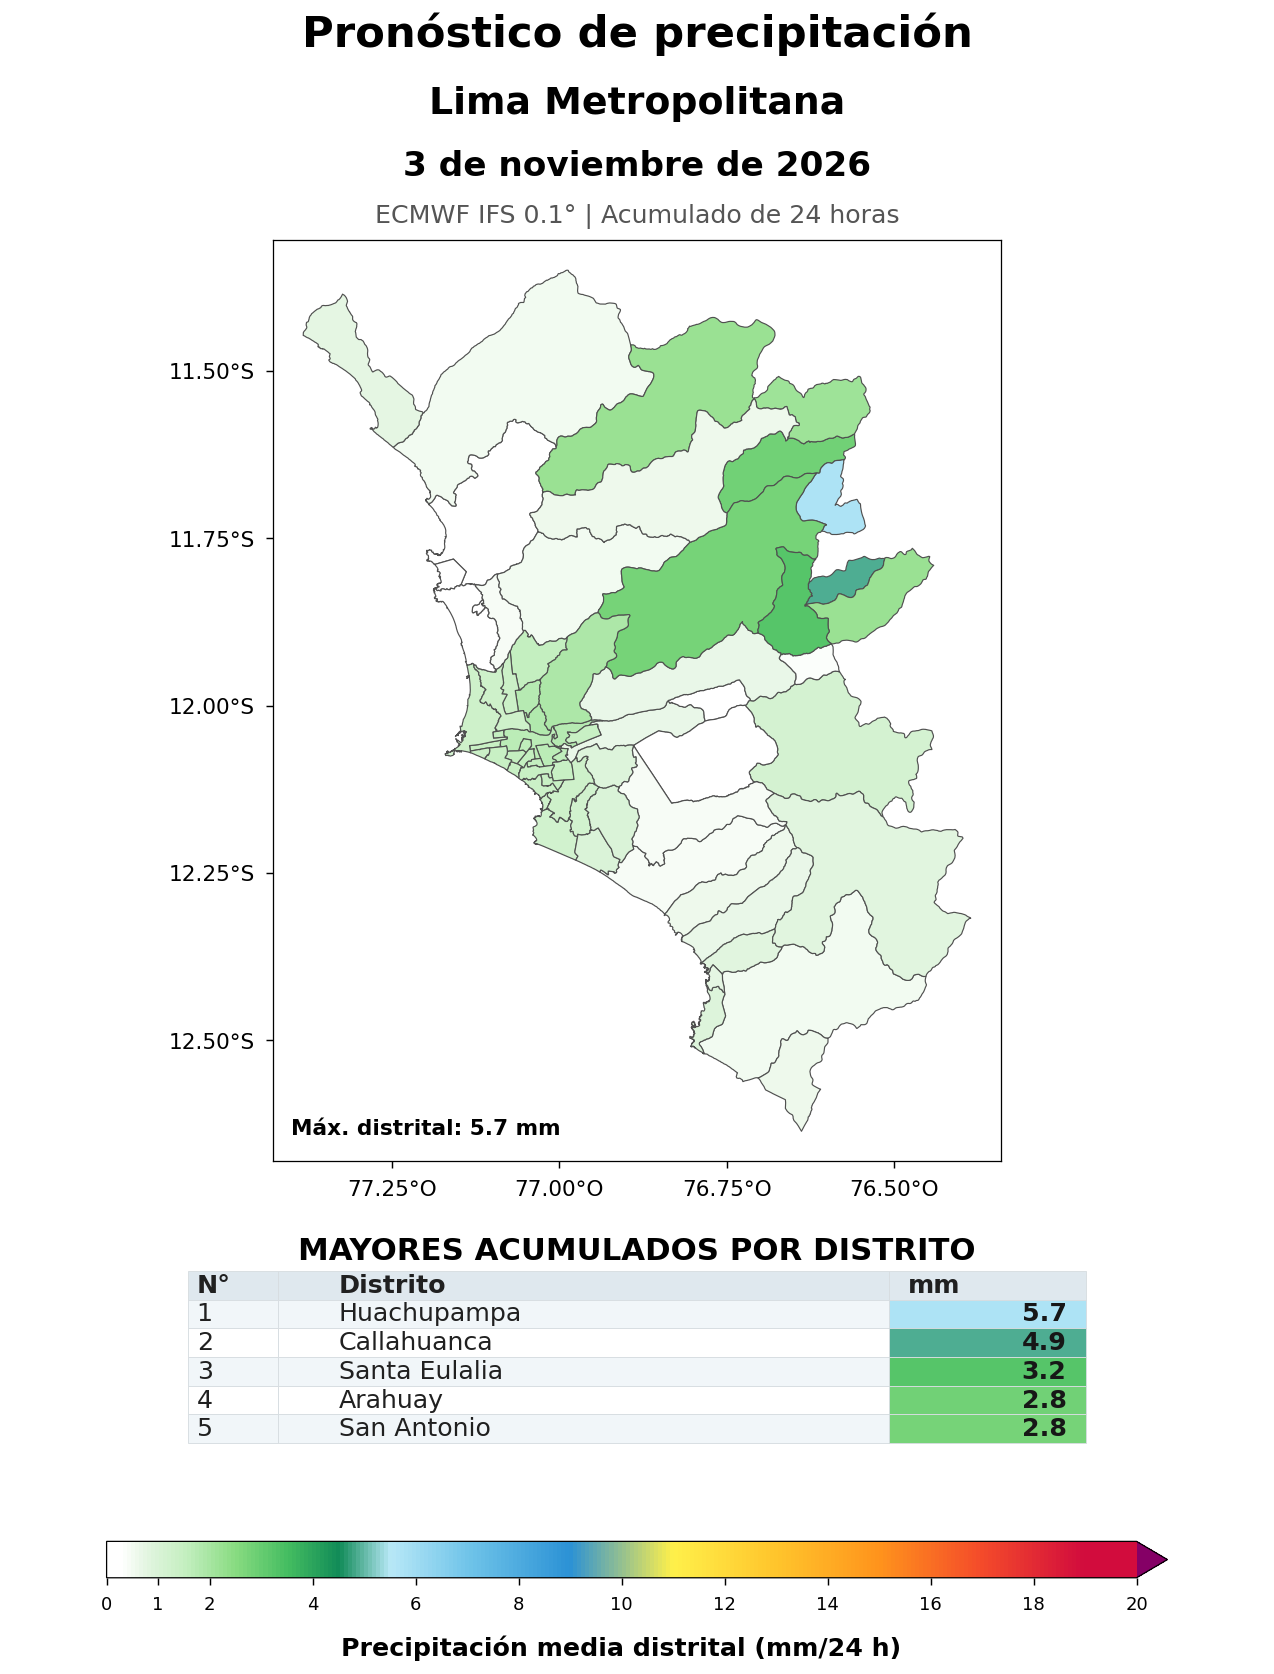

Mapa 2/5: Precipitacion_Distrital_Lima_20261104_ECMWF_IFS.png


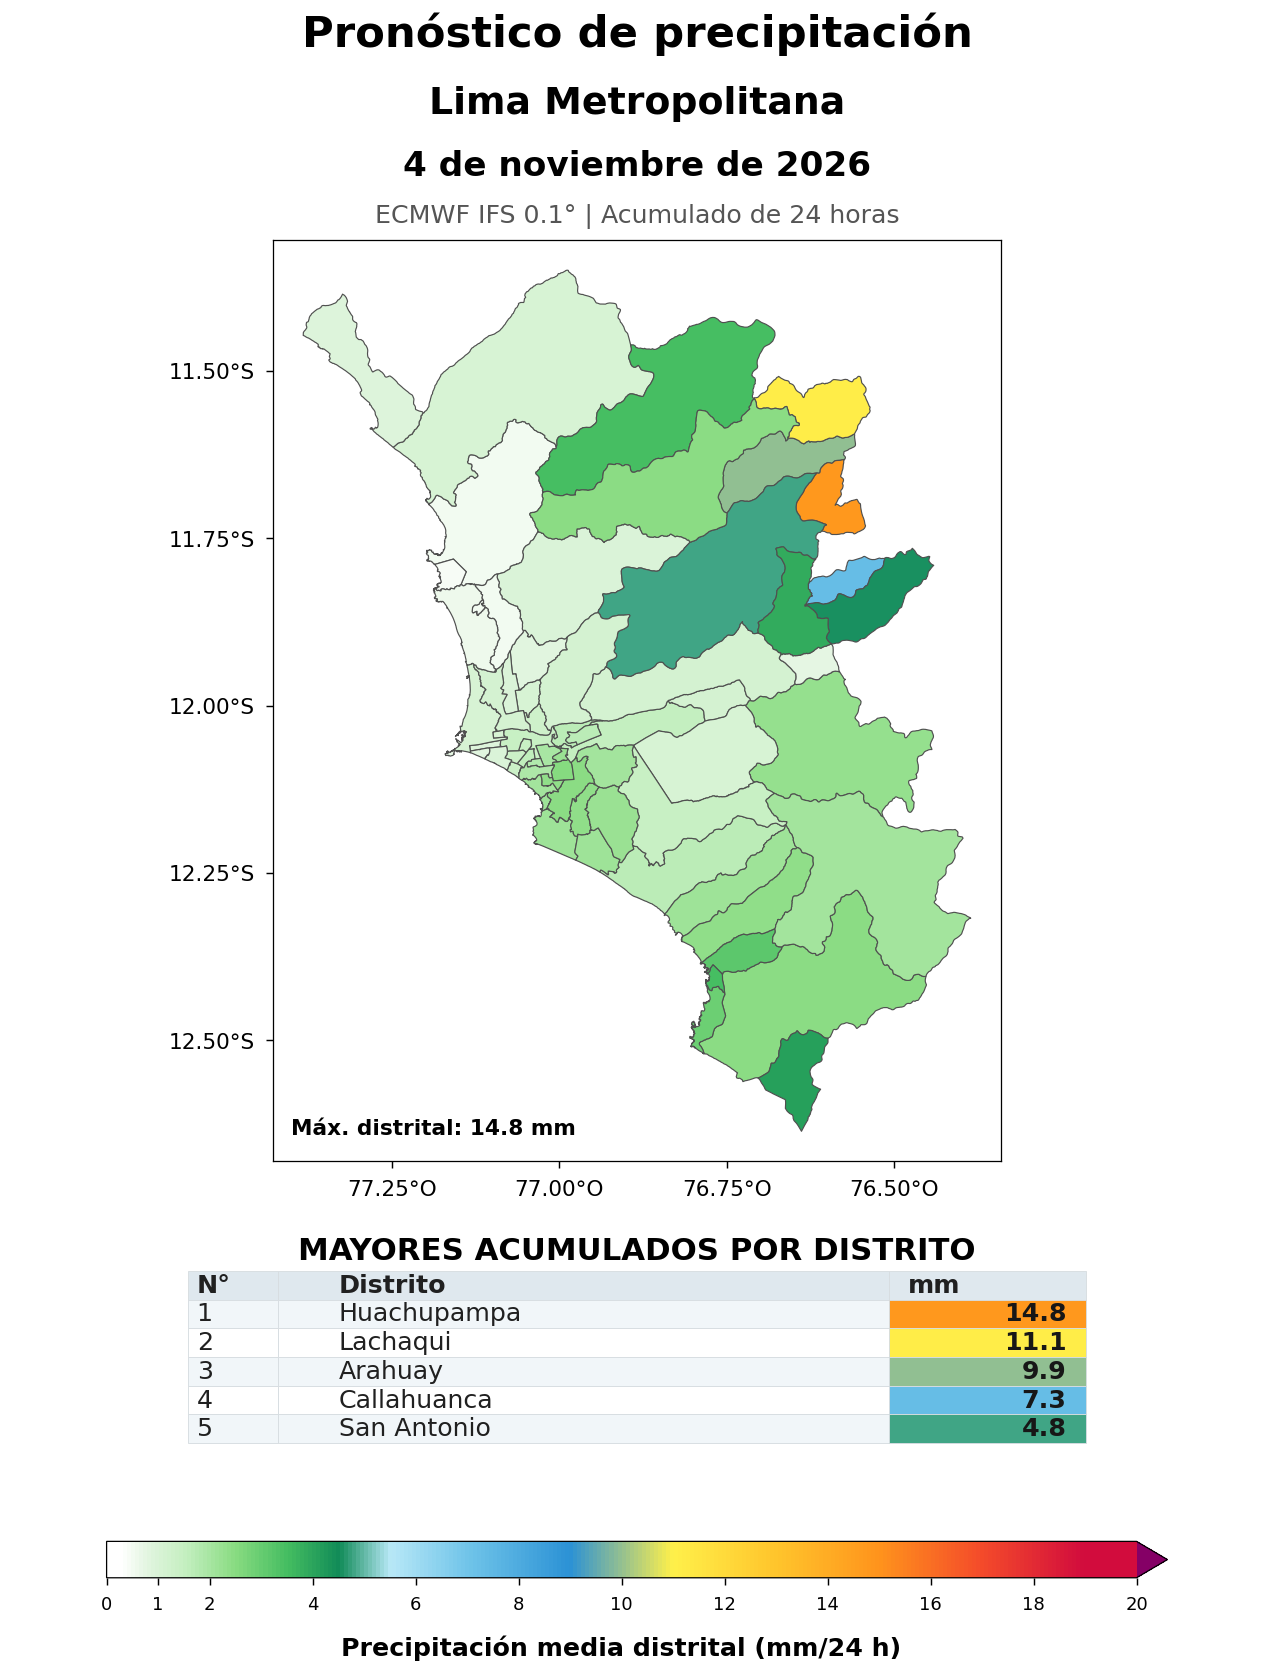

Mapa 3/5: Precipitacion_Distrital_Lima_20261105_ECMWF_IFS.png


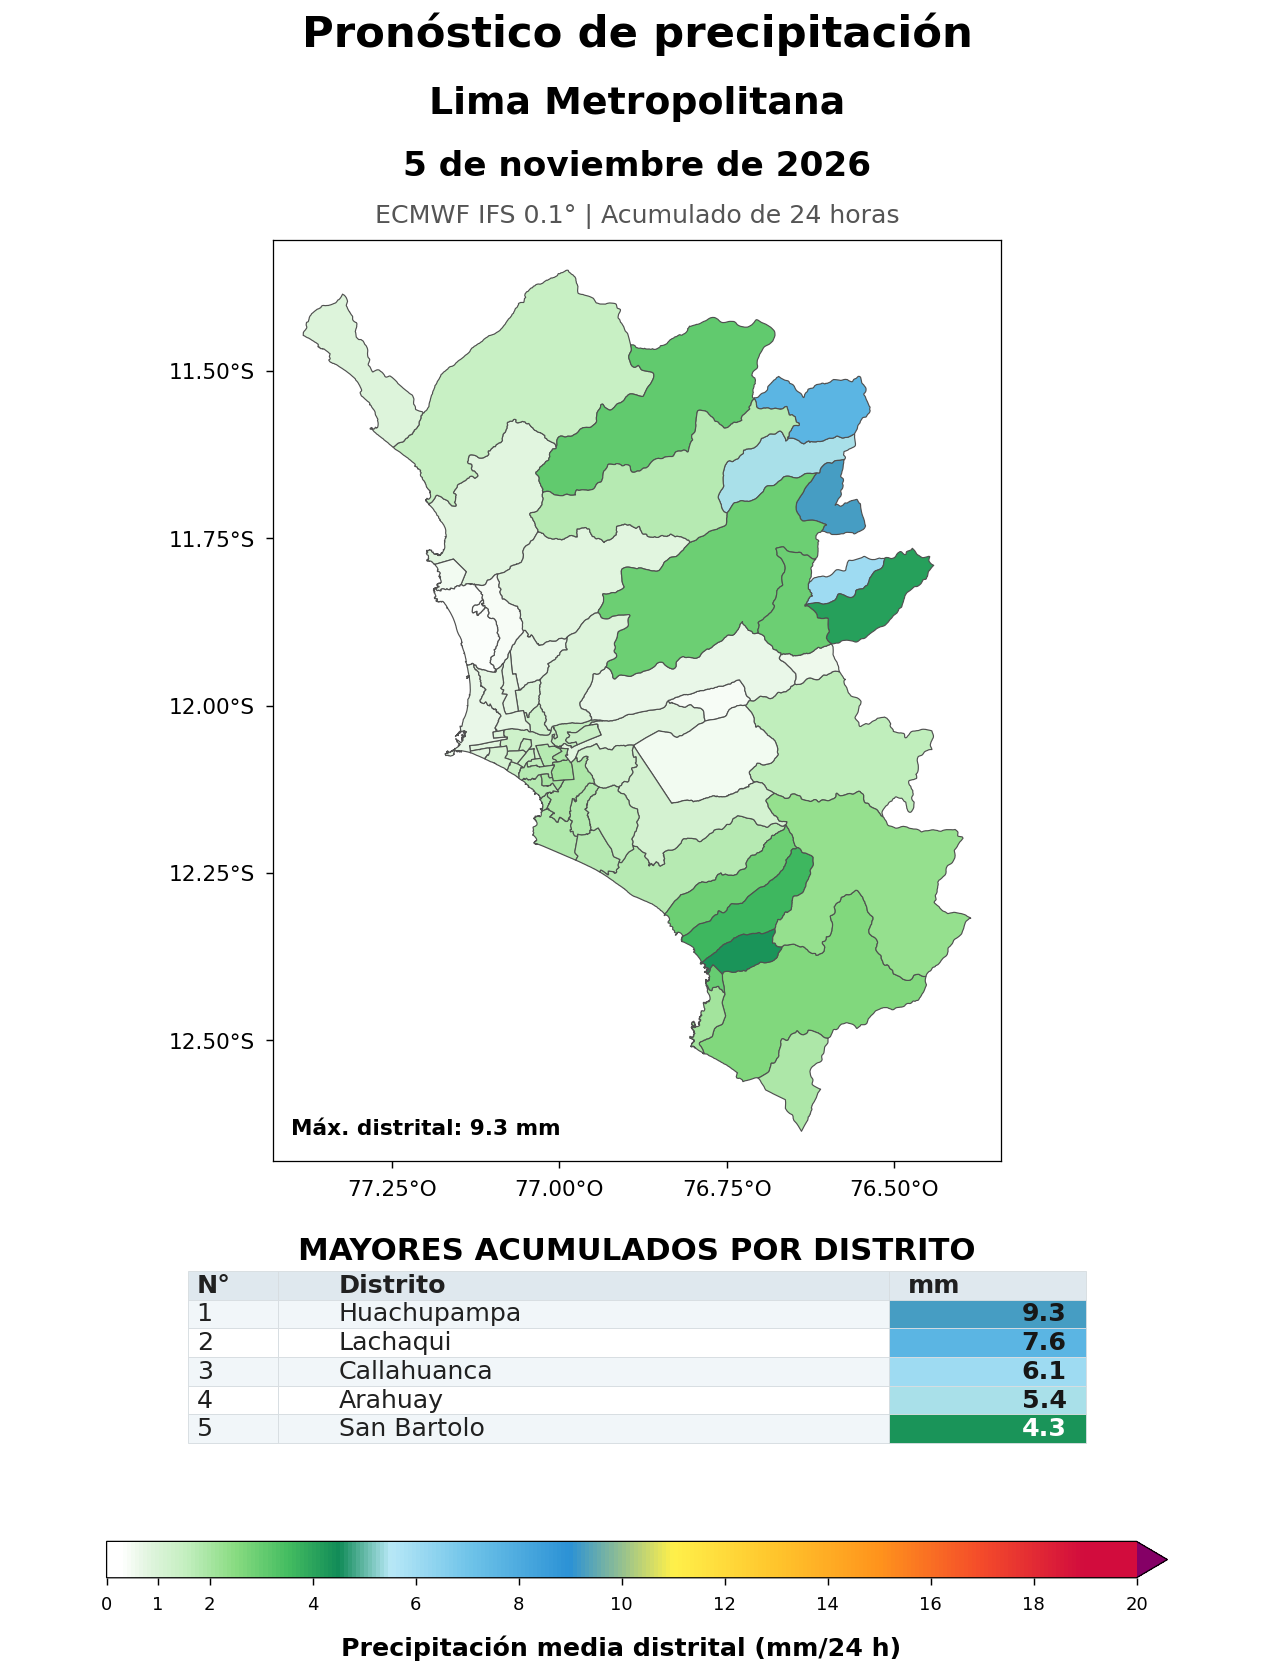

Mapa 4/5: Precipitacion_Distrital_Lima_20261106_ECMWF_IFS.png


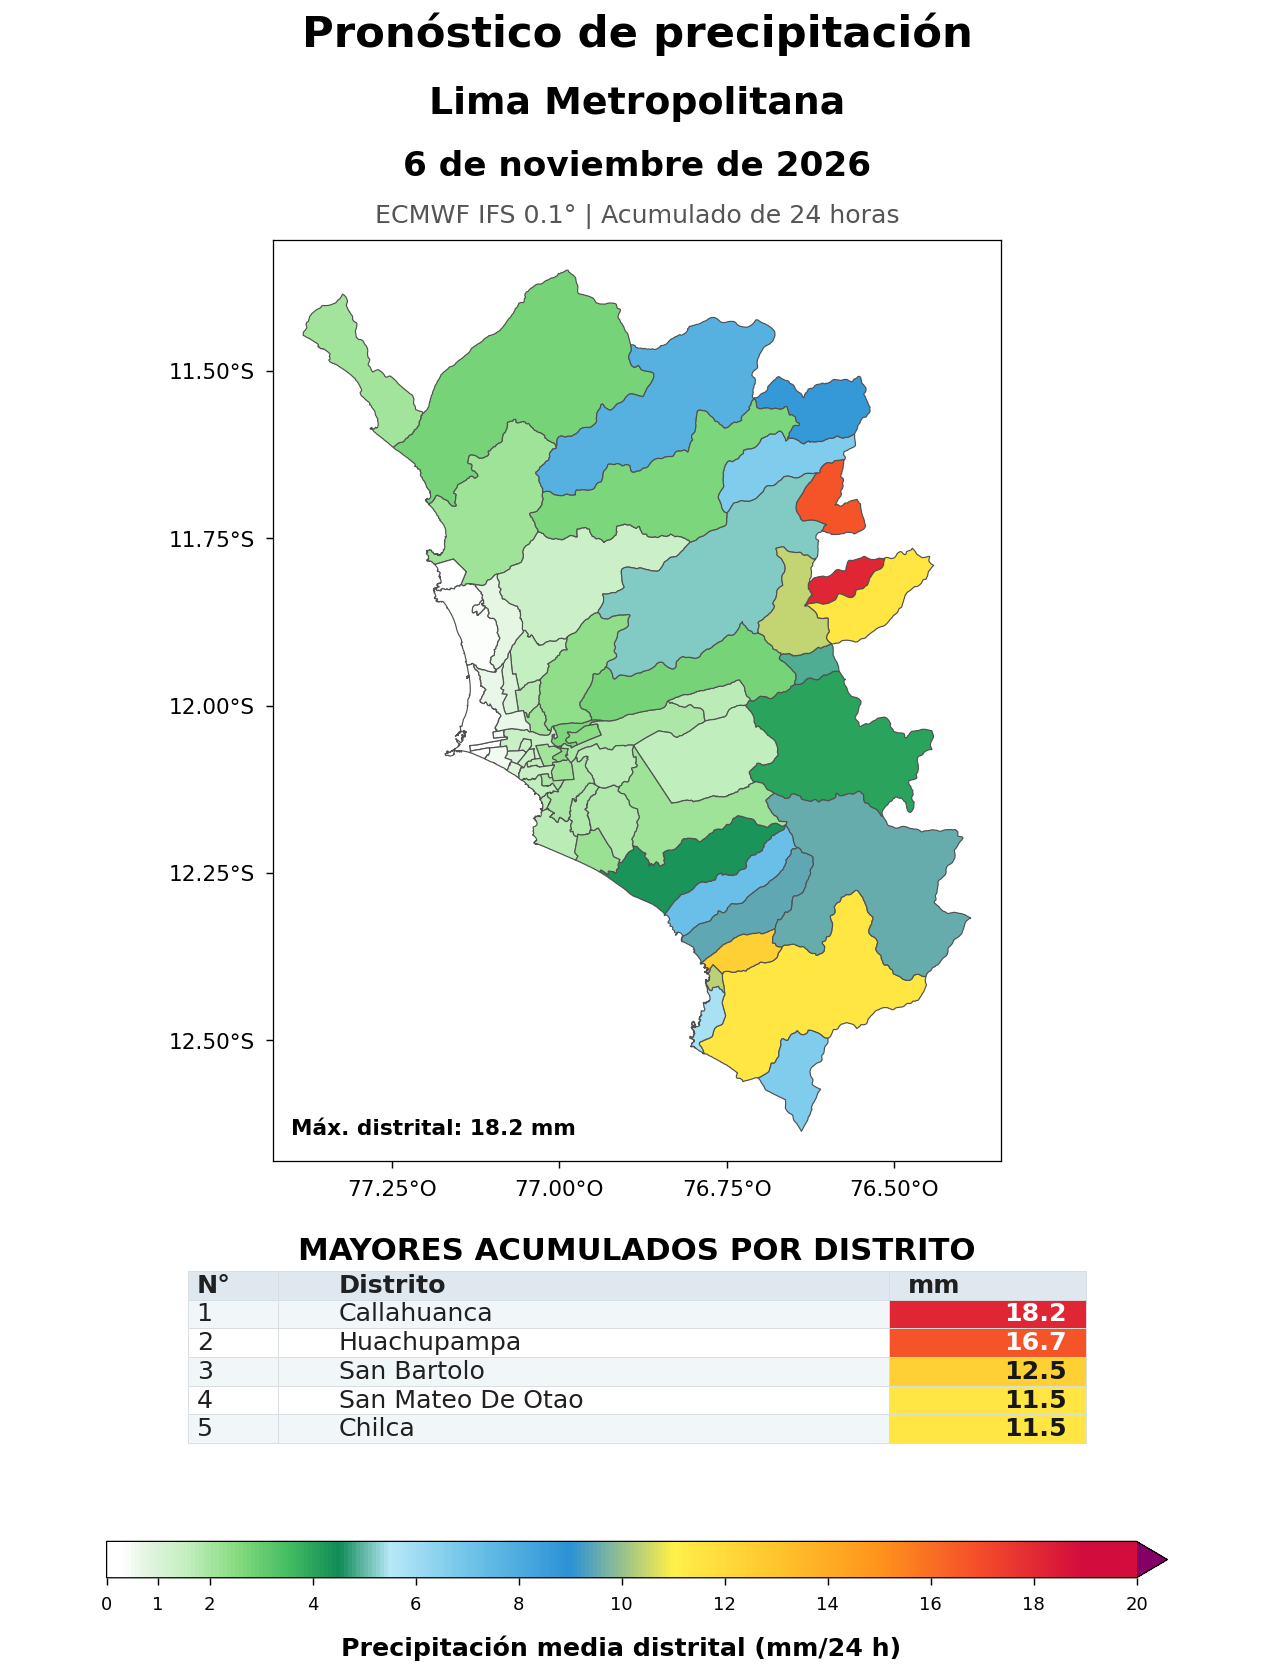

Mapa 5/5: Precipitacion_Distrital_Lima_20261107_ECMWF_IFS.png


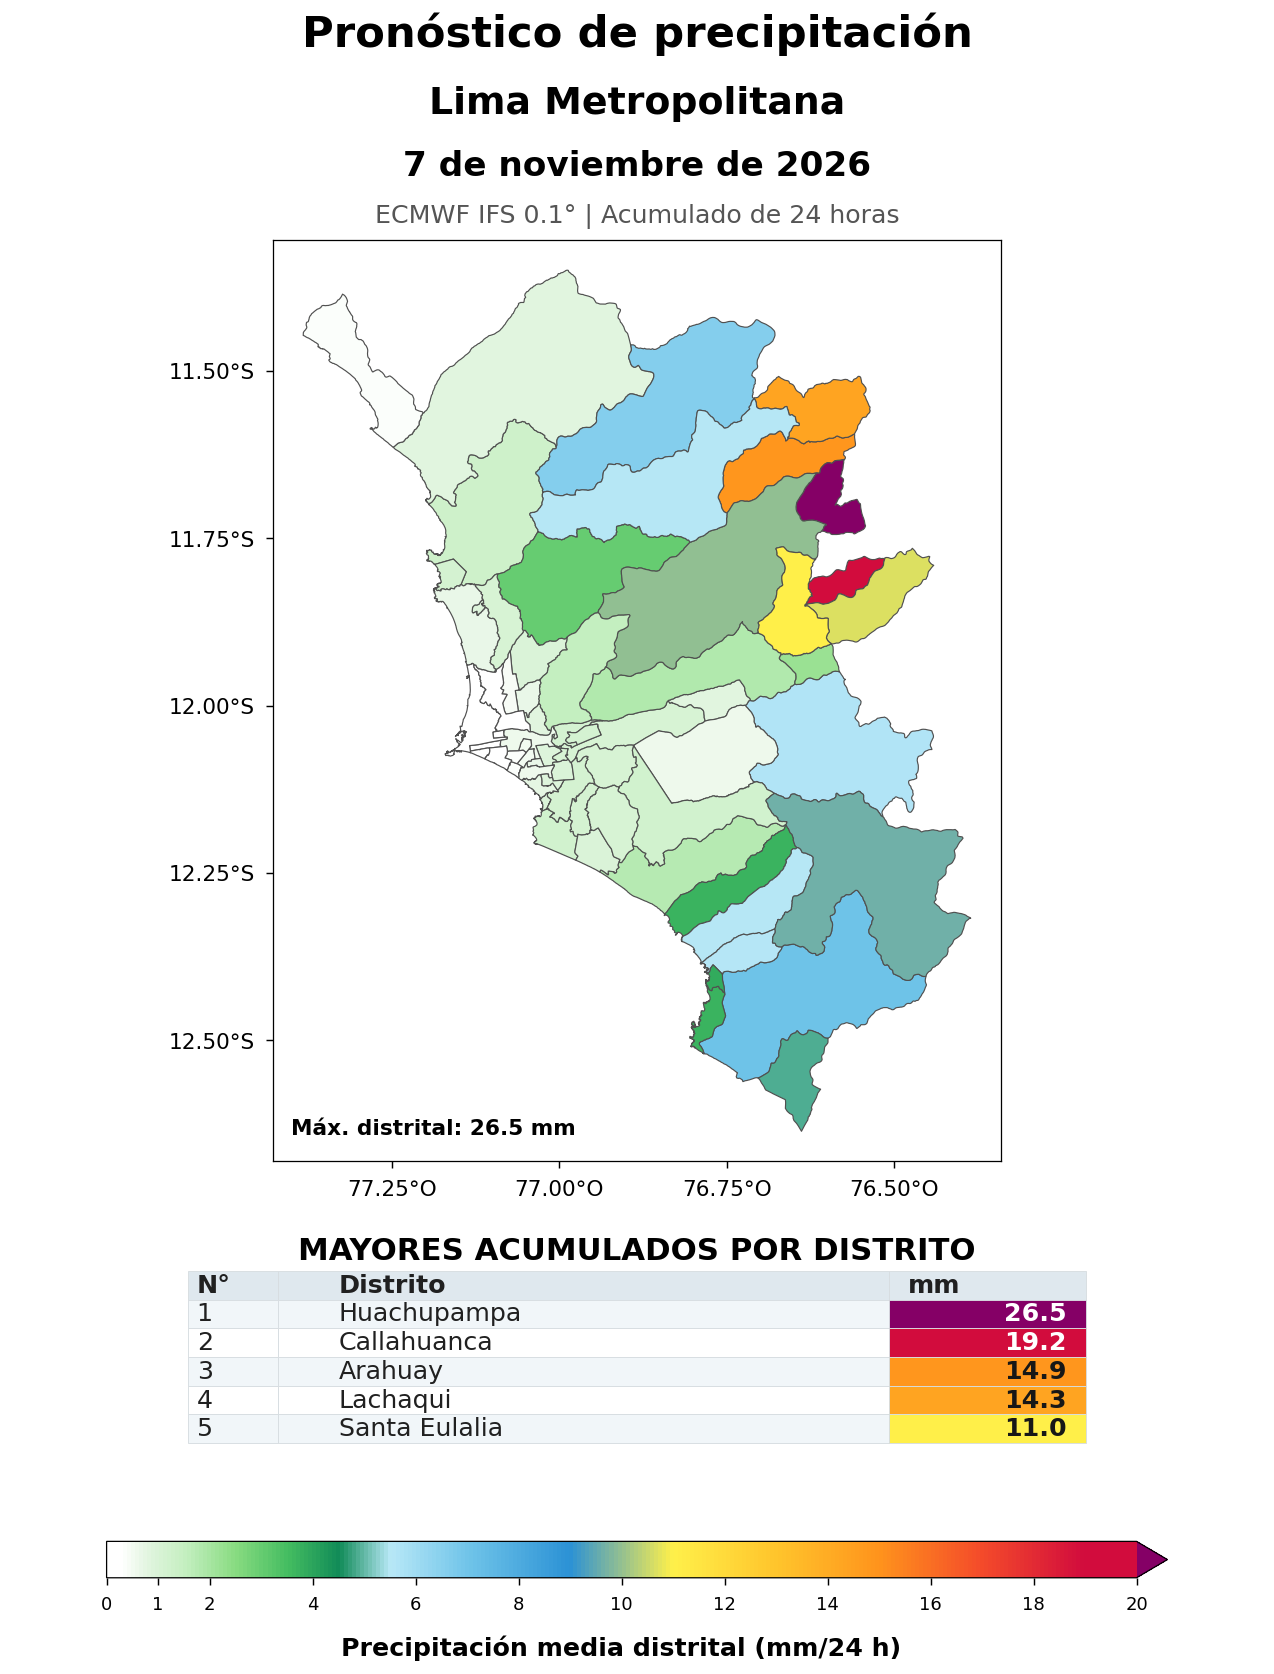


CSV generado: /content/drive/MyDrive/PRONOSTICO_ECMWF_LIMA/PRECIPITACION_DISTRITAL/Precipitacion_Todos_Distritos.csv

GENERANDO GEOPACKAGE...
GeoPackage generado correctamente: /content/drive/MyDrive/PRONOSTICO_ECMWF_LIMA/PRECIPITACION_DISTRITAL/Precipitacion_Distritos_ECMWF.gpkg
Campos: ['DISTRITO', 'geometry', 'DIA_1_MM', 'DIA_2_MM', 'DIA_3_MM', 'DIA_4_MM', 'DIA_5_MM', 'TOTAL_5DIAS_MM']

ZIP generado: /content/drive/MyDrive/PRONOSTICO_ECMWF_LIMA/PRECIPITACION_DISTRITAL/Pronostico_Precipitacion_Distrital_5dias.zip

TABLA DE PRECIPITACIÓN DE TODOS LOS DISTRITOS


,Distrito,DIA_1_MM,DIA_2_MM,DIA_3_MM,DIA_4_MM,DIA_5_MM,TOTAL_5DIAS_MM
19,HUACHUPAMPA,5.718327,14.774725,9.258614,16.741961,26.488547,72.982175
8,CALLAHUANCA,4.888962,7.274969,6.050429,18.189573,19.235273,55.639205
27,LACHAQUI,2.122448,11.121407,7.622028,8.742553,14.341659,43.950096
2,ARAHUAY,2.828663,9.937608,5.419708,6.660398,14.896530,39.742907
52,SAN MATEO DE OTAO,2.214880,4.596028,4.080568,11.458138,10.686699,33.036313
...,...,...,...,...,...,...,...
39,PUENTE PIEDRA,0.416144,0.518164,0.408938,0.745559,1.019203,3.108007
25,LA PUNTA,1.152893,0.721955,0.623118,0.097097,0.000000,2.595064
58,SANTA ROSA,0.121067,0.454963,0.474663,0.280990,1.165447,2.497131
34,MI PERU,0.122070,0.469111,0.349931,0.474649,0.925635,2.341396



RANKING TOP 5 POR DÍA


,Dia,Ranking,Distrito,PP_media_mm,PP_max_mm,Cobertura_pct
0,1,1,HUACHUPAMPA,5.718327,6.787109,100.0
1,1,2,CALLAHUANCA,4.888962,7.080078,100.0
2,1,3,SANTA EULALIA,3.213013,7.031250,100.0
3,1,4,ARAHUAY,2.828663,4.760742,100.0
4,1,5,SAN ANTONIO,2.758929,6.933594,100.0
66,2,1,HUACHUPAMPA,14.774725,16.845703,100.0
67,2,2,LACHAQUI,11.121407,13.232422,100.0
68,2,3,ARAHUAY,9.937608,14.208984,100.0
69,2,4,CALLAHUANCA,7.274969,10.053711,100.0
70,2,5,SAN ANTONIO,4.797316,15.332031,100.0



PROCESAMIENTO FINALIZADO
Distritos: 66
Mapas generados: 5
Interpolación: bilineal factor 5
Resolución: 300 dpi
CSV: /content/drive/MyDrive/PRONOSTICO_ECMWF_LIMA/PRECIPITACION_DISTRITAL/Precipitacion_Todos_Distritos.csv
GeoPackage: /content/drive/MyDrive/PRONOSTICO_ECMWF_LIMA/PRECIPITACION_DISTRITAL/Precipitacion_Distritos_ECMWF.gpkg
ZIP: /content/drive/MyDrive/PRONOSTICO_ECMWF_LIMA/PRECIPITACION_DISTRITAL/Pronostico_Precipitacion_Distrital_5dias.zip
Carpeta: /content/drive/MyDrive/PRONOSTICO_ECMWF_LIMA/PRECIPITACION_DISTRITAL


In [ ]:

# ======================================================================
# PRONÓSTICO DE PRECIPITACIÓN POR DISTRITO
# LIMA METROPOLITANA - ECMWF IFS 0.1°
#
# GOOGLE COLAB - CÓDIGO COMPLETO CORREGIDO
#
# PRODUCTOS:
#   1. Cinco mapas distritales PNG (300 dpi)
#   2. Ranking TOP 5 debajo de cada mapa
#   3. CSV de todos los distritos
#   4. GeoPackage con valores de los cinco días
#   5. ZIP con todos los productos
#
# METODOLOGÍA:
#   - Precipitación ECMWF IFS 0.1°
#   - Acumulados de 24 horas
#   - Interpolación bilineal, factor 5
#   - Promedio distrital ponderado por área
#   - Sin filtro gaussiano
#   - Únicamente Lima_distritos.shp
#
# IMPORTANTE:
# La interpolación no incrementa la resolución física del ECMWF.
# Los valores son estimaciones medias por distrito.
# ======================================================================


# ======================================================================
# 0. INSTALAR DEPENDENCIAS
# ======================================================================

import sys
import subprocess

subprocess.run(
    [
        sys.executable, "-m", "pip", "install", "-q",
        "ecmwf-opendata",
        "cfgrib",
        "eccodes",
        "xarray",
        "geopandas",
        "pyogrio",
        "matplotlib",
        "shapely",
        "pyproj",
        "pandas"
    ],
    check=True
)


# ======================================================================
# 1. IMPORTACIONES
# ======================================================================

import os
import zipfile
import tempfile
import warnings
import unicodedata

from pathlib import Path
from zoneinfo import ZoneInfo

import numpy as np
import pandas as pd
import geopandas as gpd
import xarray as xr

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.ticker as mticker

from matplotlib.cm import ScalarMappable
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Patch

from shapely.geometry import box

from ecmwf.opendata import Client

from IPython.display import display
from google.colab import drive

warnings.filterwarnings(
    "ignore",
    category=FutureWarning
)


# ======================================================================
# 2. CONFIGURACIÓN
# ======================================================================

drive.mount("/content/drive")

RUTA_SALIDA = Path(
    "/content/drive/MyDrive/"
    "PRONOSTICO_ECMWF_LIMA/"
    "PRECIPITACION_DISTRITAL"
)

RUTA_SALIDA.mkdir(
    parents=True,
    exist_ok=True
)

REPO = Path("/content/S2S-PER")

URL_REPO = (
    "https://github.com/Jorgellamocca/S2S-PER.git"
)

TZ_PERU = ZoneInfo("America/Lima")

NUM_DIAS = 5
TOP_N = 5

FACTOR_INTERPOLACION = 5

DPI_SALIDA = 300

ANCHO_FIGURA = 12
ALTO_FIGURA = 14

MARGEN_LON = 0.045
MARGEN_LAT = 0.045

CRS_AREA = "EPSG:6933"

COLOR_BORDES = "#505050"
COLOR_SIN_DATOS = "#E5E5E5"

MESES = [
    "enero",
    "febrero",
    "marzo",
    "abril",
    "mayo",
    "junio",
    "julio",
    "agosto",
    "septiembre",
    "octubre",
    "noviembre",
    "diciembre"
]

print("Directorio de salida:", RUTA_SALIDA)


# ======================================================================
# 3. FUNCIONES AUXILIARES
# ======================================================================

def buscar_archivo(carpeta, nombre):

    encontrados = [
        p for p in carpeta.iterdir()
        if p.name.lower() == nombre.lower()
    ]

    if not encontrados:

        raise FileNotFoundError(
            f"No se encontró {nombre} en {carpeta}"
        )

    return encontrados[0]


def fecha_espanol(fecha):

    return (
        f"{fecha.day} de "
        f"{MESES[fecha.month - 1]}"
    )


def normalizar_texto(texto):

    texto = str(texto).strip()

    return "".join(
        c for c in unicodedata.normalize(
            "NFD",
            texto
        )
        if unicodedata.category(c) != "Mn"
    ).upper()


def formato_longitud(x, pos=None):

    return (
        f"{abs(x):.2f}°"
        f"{'O' if x < 0 else 'E'}"
    )


def formato_latitud(y, pos=None):

    return (
        f"{abs(y):.2f}°"
        f"{'S' if y < 0 else 'N'}"
    )


def ticks_coordenadas(
    minimo,
    maximo,
    paso=0.25
):

    inicio = (
        np.ceil(minimo / paso) * paso
    )

    return np.arange(
        inicio,
        maximo + 0.0001,
        paso
    )


def bordes_grilla(coordenadas):

    c = np.asarray(
        coordenadas,
        dtype=float
    )

    medios = (
        c[:-1] + c[1:]
    ) / 2

    primero = (
        c[0] - (c[1] - c[0]) / 2
    )

    ultimo = (
        c[-1] + (c[-1] - c[-2]) / 2
    )

    return np.concatenate(
        [
            [primero],
            medios,
            [ultimo]
        ]
    )


def interpolar_bilineal(
    campo,
    lat,
    lon,
    factor=5
):

    da = xr.DataArray(
        np.asarray(campo, dtype=float),
        dims=[
            "latitude",
            "longitude"
        ],
        coords={
            "latitude": lat,
            "longitude": lon
        }
    )

    lat_f = np.linspace(
        lat.min(),
        lat.max(),
        (len(lat) - 1) * factor + 1
    )

    lon_f = np.linspace(
        lon.min(),
        lon.max(),
        (len(lon) - 1) * factor + 1
    )

    da_f = da.interp(
        latitude=lat_f,
        longitude=lon_f,
        method="linear"
    )

    return (
        lon_f,
        lat_f,
        da_f.values
    )


def color_precipitacion(
    valor,
    cmap,
    norm
):

    if not np.isfinite(valor):

        return (
            COLOR_SIN_DATOS,
            "#202020"
        )

    if valor > norm.vmax:

        color = mcolors.to_rgba(
            "#850066"
        )

    else:

        color = cmap(
            norm(valor)
        )

    r, g, b, _ = color

    luminancia = (
        0.2126 * r
        +
        0.7152 * g
        +
        0.0722 * b
    )

    texto = (
        "#FFFFFF"
        if luminancia < 0.48
        else "#171717"
    )

    return (
        color,
        texto
    )


# ======================================================================
# 4. DESCARGAR O ACTUALIZAR SHAPEFILE
# ======================================================================

print("\nACTUALIZANDO SHAPEFILE...")

if not (REPO / ".git").exists():

    subprocess.run(
        [
            "git",
            "clone",
            URL_REPO,
            str(REPO)
        ],
        check=True
    )

else:

    resultado = subprocess.run(
        [
            "git",
            "-C",
            str(REPO),
            "pull",
            "--ff-only"
        ],
        capture_output=True,
        text=True
    )

    if resultado.returncode != 0:

        print(
            "No se pudo actualizar el repositorio."
        )

        print(
            "Se utilizará la copia local."
        )

SHAPE_DISTRITOS = buscar_archivo(
    REPO / "shape",
    "Lima_distritos.shp"
)

print("Shapefile:", SHAPE_DISTRITOS)


# ======================================================================
# 5. LEER Y PREPARAR DISTRITOS
# ======================================================================

gdf = gpd.read_file(
    SHAPE_DISTRITOS
)

if gdf.crs is None:

    raise ValueError(
        "El shapefile no tiene CRS definido."
    )

gdf = gdf.to_crs(
    "EPSG:4326"
)

gdf = gdf[
    gdf.geometry.notna()
    &
    ~gdf.geometry.is_empty
].copy()

gdf["geometry"] = (
    gdf.geometry.make_valid()
)

columnas = {
    normalizar_texto(c): c
    for c in gdf.columns
}

col_distrito = None

for candidato in [
    "DISTRITO",
    "NOMBDIST",
    "NOMB_DIST",
    "NOM_DIST",
    "NOMBRE"
]:

    if candidato in columnas:

        col_distrito = (
            columnas[candidato]
        )

        break

if col_distrito is None:

    raise ValueError(
        "No se encontró el campo de distrito. "
        f"Columnas disponibles: {list(gdf.columns)}"
    )

gdf["DISTRITO"] = (
    gdf[col_distrito]
    .astype(str)
    .str.strip()
)

gdf = gdf[
    ~gdf["DISTRITO"]
    .str.upper()
    .isin(["", "NAN", "NONE"])
].copy()

# Conservar solo nombre y geometría.
# Evita duplicidad de columnas en GeoPackage.

gdf = gdf[
    ["DISTRITO", "geometry"]
].copy()

gdf = gdf.dissolve(
    by="DISTRITO",
    as_index=False
)

gdf = gdf[
    gdf.geometry.notna()
    &
    ~gdf.geometry.is_empty
].copy()

print(
    "Número de distritos:",
    len(gdf)
)


# ======================================================================
# 6. EXTENSIÓN GEOGRÁFICA
# ======================================================================

xmin, ymin, xmax, ymax = (
    gdf.total_bounds
)

LON_MIN = xmin - MARGEN_LON
LON_MAX = xmax + MARGEN_LON

LAT_MIN = ymin - MARGEN_LAT
LAT_MAX = ymax + MARGEN_LAT


# ======================================================================
# 7. CONSULTAR ÚLTIMA CORRIDA ECMWF
# ======================================================================

print("\nCONSULTANDO ECMWF IFS 0.1°...")

client = Client(
    source="ecmwf",
    model="ifs",
    resol="0p1"
)

candidatas = []

for hora in [0, 12]:

    try:

        ultima = client.latest(
            time=hora,
            stream="oper",
            type="fc",
            levtype="sfc",
            step=120,
            param="tp"
        )

        fecha = pd.Timestamp(
            ultima
        )

        if fecha.tzinfo is None:

            fecha = fecha.tz_localize(
                "UTC"
            )

        else:

            fecha = fecha.tz_convert(
                "UTC"
            )

        candidatas.append(
            fecha
        )

    except Exception as error:

        print(
            f"Ciclo {hora:02d}:",
            str(error)[:120]
        )

if not candidatas:

    raise RuntimeError(
        "No se encontró una corrida ECMWF disponible."
    )

inicio_utc = max(
    candidatas
)

FECHA = inicio_utc.strftime(
    "%Y-%m-%d"
)

HORA = inicio_utc.hour

print(
    "Corrida ECMWF:",
    inicio_utc
)


# ======================================================================
# 8. DESCARGAR PRECIPITACIÓN
# ======================================================================

PASOS = [
    24,
    48,
    72,
    96,
    120
]

temporal = tempfile.TemporaryDirectory()

GRIB = os.path.join(
    temporal.name,
    "ecmwf_ifs_tp_5dias.grib2"
)

print("\nDESCARGANDO PRECIPITACIÓN...")

client.retrieve(
    date=FECHA,
    time=HORA,
    stream="oper",
    type="fc",
    levtype="sfc",
    step=PASOS,
    param="tp",
    target=GRIB
)

print(
    "Descarga completada:",
    round(
        os.path.getsize(GRIB) / 1024**2,
        2
    ),
    "MB"
)


# ======================================================================
# 9. ABRIR GRIB
# ======================================================================

ds = xr.open_dataset(
    GRIB,
    engine="cfgrib",
    backend_kwargs={
        "indexpath": ""
    }
)

tp = ds["tp"]

if float(
    tp.longitude.max()
) > 180:

    tp = tp.assign_coords(
        longitude=(
            (tp.longitude + 180) % 360
        ) - 180
    )

tp = (
    tp.sortby("latitude")
      .sortby("longitude")
)

tp = tp.sel(
    latitude=slice(
        LAT_MIN - 0.20,
        LAT_MAX + 0.20
    ),
    longitude=slice(
        LON_MIN - 0.20,
        LON_MAX + 0.20
    )
)

lat = np.asarray(
    tp.latitude.values,
    dtype=float
)

lon = np.asarray(
    tp.longitude.values,
    dtype=float
)

if len(lat) < 2 or len(lon) < 2:

    raise ValueError(
        "La grilla ECMWF no cubre suficientemente "
        "el área de estudio."
    )

inicio_utc = pd.Timestamp(
    tp.time.values
)

if inicio_utc.tzinfo is None:

    inicio_utc = (
        inicio_utc.tz_localize("UTC")
    )

else:

    inicio_utc = (
        inicio_utc.tz_convert("UTC")
    )


# ======================================================================
# 10. ACUMULADOS DE 24 HORAS
# ======================================================================

pp_diaria = []
periodos = []

for i, paso_final in enumerate(
    PASOS
):

    paso_inicial = i * 24

    final = (
        tp.sel(
            step=np.timedelta64(
                paso_final,
                "h"
            )
        ).values * 1000.0
    )

    if i == 0:

        diario = final.copy()

    else:

        inicial = (
            tp.sel(
                step=np.timedelta64(
                    paso_inicial,
                    "h"
                )
            ).values * 1000.0
        )

        diario = (
            final - inicial
        )

    diario = np.where(
        diario >= -0.01,
        np.maximum(diario, 0),
        np.nan
    )

    pp_diaria.append(
        diario
    )

    fecha_inicio = (
        inicio_utc
        +
        pd.Timedelta(
            hours=paso_inicial
        )
    ).tz_convert(
        TZ_PERU
    )

    fecha_fin = (
        inicio_utc
        +
        pd.Timedelta(
            hours=paso_final
        )
    ).tz_convert(
        TZ_PERU
    )

    periodos.append({
        "inicio_peru": fecha_inicio,
        "fin_peru": fecha_fin
    })

pp = np.stack(
    pp_diaria,
    axis=0
)

print("\nPERIODOS DE PRONÓSTICO")

for i, periodo in enumerate(
    periodos
):

    print(
        f"Día {i + 1}: "
        f"{periodo['inicio_peru']} "
        f"a {periodo['fin_peru']}"
    )


# ======================================================================
# 11. INTERPOLACIÓN BILINEAL
# ======================================================================

print("\nINTERPOLANDO CAMPOS...")

campos_interpolados = []

for dia in range(
    NUM_DIAS
):

    lon_f, lat_f, campo_f = (
        interpolar_bilineal(
            pp[dia],
            lat,
            lon,
            factor=FACTOR_INTERPOLACION
        )
    )

    campos_interpolados.append(
        campo_f
    )

print(
    "Dimensiones interpoladas:",
    len(lat_f),
    "x",
    len(lon_f)
)


# ======================================================================
# 12. CREAR CELDAS DE LA GRILLA INTERPOLADA
# ======================================================================

lon_b = bordes_grilla(
    lon_f
)

lat_b = bordes_grilla(
    lat_f
)

celdas = []

for iy in range(
    len(lat_f)
):

    for ix in range(
        len(lon_f)
    ):

        celdas.append({
            "iy": iy,
            "ix": ix,
            "geometry": box(
                lon_b[ix],
                lat_b[iy],
                lon_b[ix + 1],
                lat_b[iy + 1]
            )
        })

grid = gpd.GeoDataFrame(
    celdas,
    geometry="geometry",
    crs="EPSG:4326"
)


# ======================================================================
# 13. INTERSECCIÓN CON POLÍGONOS DISTRITALES
# ======================================================================

print("\nCALCULANDO INTERSECCIONES DISTRITALES...")

distritos_area = gdf.to_crs(
    CRS_AREA
)

grid_area = grid.to_crs(
    CRS_AREA
)

inter = gpd.overlay(
    distritos_area[
        ["DISTRITO", "geometry"]
    ],
    grid_area[
        ["iy", "ix", "geometry"]
    ],
    how="intersection",
    keep_geom_type=False
)

inter["area_m2"] = (
    inter.geometry.area
)

inter = inter[
    inter["area_m2"] > 0
].copy()

print(
    "Intersecciones:",
    len(inter)
)


# ======================================================================
# 14. PRECIPITACIÓN MEDIA POR DISTRITO
# ======================================================================

print("\nCALCULANDO PRECIPITACIÓN POR DISTRITO...")

resultados = []

for dia in range(
    NUM_DIAS
):

    campo = campos_interpolados[
        dia
    ]

    for nombre, grupo in inter.groupby(
        "DISTRITO"
    ):

        iy = grupo[
            "iy"
        ].to_numpy(
            dtype=int
        )

        ix = grupo[
            "ix"
        ].to_numpy(
            dtype=int
        )

        valores = campo[
            iy,
            ix
        ]

        areas = grupo[
            "area_m2"
        ].to_numpy(
            dtype=float
        )

        validos = (
            np.isfinite(valores)
            &
            np.isfinite(areas)
            &
            (areas > 0)
        )

        if np.any(
            validos
        ):

            media = np.average(
                valores[validos],
                weights=areas[validos]
            )

            maxima = np.max(
                valores[validos]
            )

            cobertura = (
                100
                *
                areas[validos].sum()
                /
                areas.sum()
            )

        else:

            media = np.nan
            maxima = np.nan
            cobertura = 0.0

        resultados.append({
            "Dia": dia + 1,
            "Distrito": nombre,
            "PP_media_mm": float(media),
            "PP_max_mm": float(maxima),
            "Cobertura_pct": float(cobertura)
        })

tabla = pd.DataFrame(
    resultados
)

tabla = tabla.sort_values(
    [
        "Dia",
        "PP_media_mm"
    ],
    ascending=[
        True,
        False
    ],
    na_position="last"
).reset_index(
    drop=True
)

tabla["Ranking"] = (
    tabla.groupby(
        "Dia"
    ).cumcount() + 1
)

print(
    "Distritos evaluados:",
    tabla["Distrito"].nunique()
)


# ======================================================================
# 15. PALETA DE COLORES
# ======================================================================

niveles = [
    0,
    0.5,
    1,
    2,
    3,
    4,
    5,
    6,
    8,
    10,
    12,
    14,
    16,
    18,
    20
]

colores = [
    "#FFFFFF",
    "#E2F5E0",
    "#C4EFC0",
    "#87DB80",
    "#43BC60",
    "#118B58",
    "#B8E8F7",
    "#70C4E9",
    "#2B91D5",
    "#FFF04A",
    "#FFC52C",
    "#FF941C",
    "#F44B2A",
    "#D20C3D"
]

puntos_medios = (
    np.array(
        niveles[:-1]
    )
    +
    np.array(
        niveles[1:]
    )
) / 2

puntos_color = [
    (0.0, colores[0])
]

puntos_color += list(
    zip(
        puntos_medios / 20,
        colores
    )
)

puntos_color += [
    (1.0, colores[-1])
]

cmap = (
    mcolors.LinearSegmentedColormap.from_list(
        "precipitacion_distrital",
        puntos_color,
        N=256
    )
)

cmap.set_over(
    "#850066"
)

cmap.set_bad(
    COLOR_SIN_DATOS
)

norm = mcolors.Normalize(
    vmin=0,
    vmax=20,
    clip=False
)


# ======================================================================
# 16. CONFIGURACIÓN DE FIGURAS
# ======================================================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "figure.dpi": 130,
    "savefig.dpi": DPI_SALIDA
})

ticks_lon = ticks_coordenadas(
    LON_MIN,
    LON_MAX
)

ticks_lat = ticks_coordenadas(
    LAT_MIN,
    LAT_MAX
)

archivos_generados = []


# ======================================================================
# 17. GENERAR LOS CINCO MAPAS
# ======================================================================

print("\nGENERANDO MAPAS DISTRITALES...")

for dia in range(
    NUM_DIAS
):

    fecha_fin = periodos[
        dia
    ]["fin_peru"]

    titulo_fecha = fecha_espanol(
        fecha_fin
    )

    fecha_archivo = (
        fecha_fin.strftime(
            "%Y%m%d"
        )
    )

    datos_dia = tabla[
        tabla["Dia"] == dia + 1
    ][
        [
            "Distrito",
            "PP_media_mm"
        ]
    ].copy()

    # Cambiar Distrito a DISTRITO antes del merge
    # para evitar columnas duplicadas.

    datos_dia = datos_dia.rename(
        columns={
            "Distrito": "DISTRITO"
        }
    )

    mapa = gdf.merge(
        datos_dia,
        on="DISTRITO",
        how="left",
        validate="one_to_one"
    )

    # --------------------------------------------------------------
    # FIGURA
    # --------------------------------------------------------------

    fig = plt.figure(
        figsize=(
            ANCHO_FIGURA,
            ALTO_FIGURA
        ),
        facecolor="white"
    )

    gs = GridSpec(
        2,
        1,
        figure=fig,
        height_ratios=[
            5.8,
            1.55
        ],
        left=0.10,
        right=0.90,
        top=0.84,
        bottom=0.16,
        hspace=0.12
    )

    # --------------------------------------------------------------
    # MAPA DISTRITAL
    # --------------------------------------------------------------

    ax = fig.add_subplot(
        gs[0, 0]
    )

    mapa.plot(
        column="PP_media_mm",
        ax=ax,
        cmap=cmap,
        norm=norm,
        edgecolor=COLOR_BORDES,
        linewidth=0.65,
        missing_kwds={
            "color": COLOR_SIN_DATOS,
            "edgecolor": COLOR_BORDES
        }
    )

    ax.set_xlim(
        LON_MIN,
        LON_MAX
    )

    ax.set_ylim(
        LAT_MIN,
        LAT_MAX
    )

    ax.set_aspect(
        "equal"
    )

    ax.set_xticks(
        ticks_lon
    )

    ax.set_yticks(
        ticks_lat
    )

    ax.xaxis.set_major_formatter(
        mticker.FuncFormatter(
            formato_longitud
        )
    )

    ax.yaxis.set_major_formatter(
        mticker.FuncFormatter(
            formato_latitud
        )
    )

    ax.set_xlabel("")
    ax.set_ylabel("")

    ax.tick_params(
        axis="both",
        labelsize=12,
        pad=6,
        length=4
    )

    # Sin cuadrícula de fondo.
    ax.grid(False)

    # --------------------------------------------------------------
    # MÁXIMO DISTRITAL
    # --------------------------------------------------------------

    maximo = mapa[
        "PP_media_mm"
    ].max()

    texto_maximo = (
        f"Máx. distrital: {maximo:.1f} mm"
        if np.isfinite(maximo)
        else "Sin datos"
    )

    ax.text(
        0.025,
        0.025,
        texto_maximo,
        transform=ax.transAxes,
        fontsize=12,
        fontweight="bold",
        ha="left",
        va="bottom",
        bbox={
            "facecolor": "white",
            "alpha": 0.92,
            "edgecolor": "none",
            "pad": 3
        },
        zorder=16
    )

    # --------------------------------------------------------------
    # TABLA DE RANKING
    # --------------------------------------------------------------

    ax_tabla = fig.add_subplot(
        gs[1, 0]
    )

    ax_tabla.axis(
        "off"
    )

    ax_tabla.text(
        0.5,
        0.98,
        "MAYORES ACUMULADOS POR DISTRITO",
        transform=ax_tabla.transAxes,
        ha="center",
        va="top",
        fontsize=17,
        fontweight="bold"
    )

    top = (
        tabla[
            tabla["Dia"] == dia + 1
        ]
        .dropna(
            subset=["PP_media_mm"]
        )
        .head(TOP_N)
        .reset_index(drop=True)
    )

    filas = []

    for _, fila in top.iterrows():

        filas.append([
            str(
                int(fila["Ranking"])
            ),
            str(
                fila["Distrito"]
            ).title(),
            f'{fila["PP_media_mm"]:.1f}'
        ])

    t = ax_tabla.table(
        cellText=filas,
        colLabels=[
            "N°",
            "Distrito",
            "mm"
        ],
        colWidths=[
            0.10,
            0.68,
            0.22
        ],
        cellLoc="left",
        colLoc="left",
        bbox=[
            0.14,
            0.14,
            0.72,
            0.70
        ]
    )

    t.auto_set_font_size(
        False
    )

    t.set_fontsize(
        14
    )

    for (fila, col), celda in (
        t.get_celld().items()
    ):

        celda.set_linewidth(
            0.5
        )

        celda.set_edgecolor(
            "#D7DDE1"
        )

        celda.PAD = 0.10

        celda.get_text().set_va(
            "center"
        )

        if fila == 0:

            celda.set_facecolor(
                "#DFE8EE"
            )

            celda.set_text_props(
                weight="bold",
                fontsize=14,
                color="#202020"
            )

        elif col == 2:

            valor = float(
                top.iloc[
                    fila - 1
                ]["PP_media_mm"]
            )

            fondo, texto = (
                color_precipitacion(
                    valor,
                    cmap,
                    norm
                )
            )

            celda.set_facecolor(
                fondo
            )

            celda.set_text_props(
                color=texto,
                weight="bold",
                fontsize=14
            )

            celda.get_text().set_ha(
                "right"
            )

        else:

            celda.set_facecolor(
                "#F1F6F9"
                if fila % 2
                else "#FFFFFF"
            )

            celda.set_text_props(
                fontsize=14,
                color="#202020"
            )

    # --------------------------------------------------------------
    # TÍTULOS
    # --------------------------------------------------------------

    fig.text(
        0.5,
        0.965,
        "Pronóstico de precipitación",
        ha="center",
        va="top",
        fontsize=24,
        fontweight="bold"
    )

    fig.text(
        0.5,
        0.925,
        "Lima Metropolitana",
        ha="center",
        va="top",
        fontsize=21,
        fontweight="bold"
    )

    fig.text(
        0.5,
        0.890,
        f"{titulo_fecha} de {fecha_fin.year}",
        ha="center",
        va="top",
        fontsize=19,
        fontweight="bold"
    )

    fig.text(
        0.5,
        0.860,
        "ECMWF IFS 0.1° | Acumulado de 24 horas",
        ha="center",
        va="top",
        fontsize=14,
        color="#555555"
    )

    # --------------------------------------------------------------
    # BARRA DE COLORES
    # --------------------------------------------------------------

    cax = fig.add_axes([
        0.16,
        0.105,
        0.68,
        0.020
    ])

    sm = ScalarMappable(
        norm=norm,
        cmap=cmap
    )

    sm.set_array([])

    cbar = fig.colorbar(
        sm,
        cax=cax,
        orientation="horizontal",
        ticks=[
            0, 1, 2, 4, 6, 8,
            10, 12, 14, 16, 18, 20
        ],
        extend="max",
        extendfrac=0.03
    )

    cbar.ax.tick_params(
        labelsize=10,
        length=4,
        pad=6
    )

    cbar.outline.set_linewidth(
        0.7
    )

    cbar.set_label(
        "Precipitación media distrital (mm/24 h)",
        fontsize=14,
        fontweight="bold",
        labelpad=12
    )

    # --------------------------------------------------------------
    # GUARDAR PNG
    # --------------------------------------------------------------

    nombre_archivo = (
        "Precipitacion_Distrital_Lima_"
        f"{fecha_archivo}_ECMWF_IFS.png"
    )

    ruta_png = (
        RUTA_SALIDA
        /
        nombre_archivo
    )

    fig.savefig(
        ruta_png,
        dpi=DPI_SALIDA,
        facecolor="white",
        bbox_inches="tight",
        pad_inches=0.15
    )

    archivos_generados.append(
        ruta_png
    )

    print(
        f"Mapa {dia + 1}/{NUM_DIAS}:",
        ruta_png.name
    )

    plt.show()
    plt.close(fig)


# ======================================================================
# 18. CSV DE TODOS LOS DISTRITOS
# ======================================================================

tabla_ancha = tabla.pivot(
    index="Distrito",
    columns="Dia",
    values="PP_media_mm"
)

tabla_ancha = tabla_ancha.reindex(
    columns=range(
        1,
        NUM_DIAS + 1
    )
)

tabla_ancha.columns = [
    f"DIA_{i}_MM"
    for i in range(
        1,
        NUM_DIAS + 1
    )
]

tabla_ancha = (
    tabla_ancha.reset_index()
)

columnas_dias = [
    f"DIA_{i}_MM"
    for i in range(
        1,
        NUM_DIAS + 1
    )
]

tabla_ancha["TOTAL_5DIAS_MM"] = (
    tabla_ancha[
        columnas_dias
    ].sum(
        axis=1,
        min_count=NUM_DIAS
    )
)

RUTA_CSV = (
    RUTA_SALIDA
    /
    "Precipitacion_Todos_Distritos.csv"
)

tabla_ancha.to_csv(
    RUTA_CSV,
    index=False,
    encoding="utf-8-sig"
)

print(
    "\nCSV generado:",
    RUTA_CSV
)


# ======================================================================
# 19. GEOPACKAGE - CORRECCIÓN DEL ERROR FIELDERROR
# ======================================================================

print("\nGENERANDO GEOPACKAGE...")

RUTA_GPKG = (
    RUTA_SALIDA
    /
    "Precipitacion_Distritos_ECMWF.gpkg"
)

# CORRECCIÓN:
# Renombrar 'Distrito' a 'DISTRITO' ANTES de unir.
# No conservar ambos campos porque GeoPackage los
# considera duplicados (ignora mayúsculas/minúsculas).

tabla_gpkg = tabla_ancha.rename(
    columns={
        "Distrito": "DISTRITO"
    }
)

columnas_exportar = [
    "DISTRITO",
    "DIA_1_MM",
    "DIA_2_MM",
    "DIA_3_MM",
    "DIA_4_MM",
    "DIA_5_MM",
    "TOTAL_5DIAS_MM"
]

tabla_gpkg = tabla_gpkg[
    columnas_exportar
].copy()

gdf_salida = gdf[
    ["DISTRITO", "geometry"]
].merge(
    tabla_gpkg,
    on="DISTRITO",
    how="left",
    validate="one_to_one"
)

# Comprobar que no existan nombres de columnas
# duplicados al ignorar mayúsculas/minúsculas.

nombres_normalizados = [
    c.casefold()
    for c in gdf_salida.columns
]

if len(nombres_normalizados) != len(
    set(nombres_normalizados)
):

    raise ValueError(
        "Existen columnas duplicadas en el GeoPackage."
    )

# Borrar archivo anterior para evitar conflictos.

if RUTA_GPKG.exists():

    RUTA_GPKG.unlink()

gdf_salida.to_file(
    RUTA_GPKG,
    layer="precipitacion_distrital",
    driver="GPKG",
    index=False
)

print(
    "GeoPackage generado correctamente:",
    RUTA_GPKG
)

print(
    "Campos:",
    gdf_salida.columns.tolist()
)


# ======================================================================
# 20. CREAR ZIP
# ======================================================================

RUTA_ZIP = (
    RUTA_SALIDA
    /
    "Pronostico_Precipitacion_Distrital_5dias.zip"
)

with zipfile.ZipFile(
    RUTA_ZIP,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as zipf:

    for archivo in archivos_generados:

        zipf.write(
            archivo,
            arcname=archivo.name
        )

    zipf.write(
        RUTA_CSV,
        arcname=RUTA_CSV.name
    )

    zipf.write(
        RUTA_GPKG,
        arcname=RUTA_GPKG.name
    )

print(
    "\nZIP generado:",
    RUTA_ZIP
)


# ======================================================================
# 21. MOSTRAR TABLAS
# ======================================================================

print(
    "\nTABLA DE PRECIPITACIÓN DE TODOS LOS DISTRITOS"
)

display(
    tabla_ancha.sort_values(
        "TOTAL_5DIAS_MM",
        ascending=False
    )
)

print(
    "\nRANKING TOP 5 POR DÍA"
)

display(
    tabla[
        (tabla["Ranking"] <= TOP_N)
        &
        tabla["PP_media_mm"].notna()
    ][
        [
            "Dia",
            "Ranking",
            "Distrito",
            "PP_media_mm",
            "PP_max_mm",
            "Cobertura_pct"
        ]
    ]
)


# ======================================================================
# 22. CERRAR ARCHIVOS
# ======================================================================

ds.close()
temporal.cleanup()


# ======================================================================
# 23. RESUMEN FINAL
# ======================================================================

print("\n" + "=" * 65)
print("PROCESAMIENTO FINALIZADO")
print("=" * 65)

print(
    "Distritos:",
    len(gdf)
)

print(
    "Mapas generados:",
    len(archivos_generados)
)

print(
    "Interpolación:",
    f"bilineal factor {FACTOR_INTERPOLACION}"
)

print(
    "Resolución:",
    DPI_SALIDA,
    "dpi"
)

print(
    "CSV:",
    RUTA_CSV
)

print(
    "GeoPackage:",
    RUTA_GPKG
)

print(
    "ZIP:",
    RUTA_ZIP
)

print(
    "Carpeta:",
    RUTA_SALIDA
)
